In [1]:
!pip install -q brian2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 84.9 MB/s eta 0:00:00


In [2]:
import brian2
print("Brian2 version:", brian2.__version__)

Brian2 version: 2.10.1


In [3]:
from brian2 import *
import numpy as np
import matplotlib.pyplot as plt

In [4]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

# Parameters
tau = 10*ms
EL = -70*mV
Vth = -50*mV
Vreset = -70*mV
R = 100*Mohm

# LIF differential equation
eqs = '''
dv/dt = (-(v - EL) + R*I)/tau : volt
I : amp
'''

# Create neuron
G = NeuronGroup(
    1,
    eqs,
    threshold='v >= Vth',
    reset='v = Vreset',
    method='exact'
)

# Initial state
G.v = EL
G.I = 250*pA

# Record membrane voltage
M = StateMonitor(
    G,
    'v',
    record=True
)

# Record spikes
spikes = SpikeMonitor(G)

# Run simulation
run(500*ms)

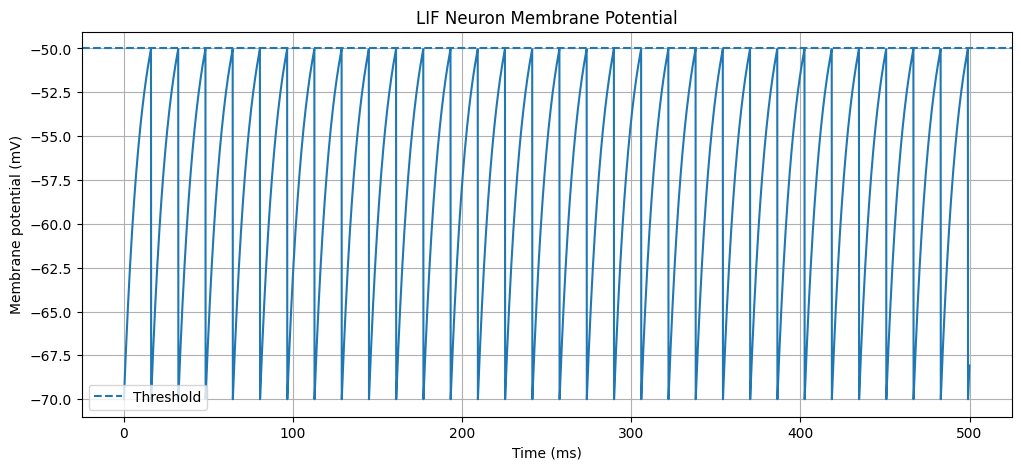

In [5]:
plt.figure(figsize=(12,5))

plt.plot(
    M.t/ms,
    M.v[0]/mV
)

plt.axhline(
    Vth/mV,
    linestyle='--',
    label='Threshold'
)

plt.xlabel("Time (ms)")
plt.ylabel("Membrane potential (mV)")
plt.title("LIF Neuron Membrane Potential")

plt.legend()
plt.grid()

plt.show()

In [6]:
print("Number of spikes:", spikes.count[0])

Number of spikes: 31


In [7]:
rate = spikes.count[0] / (500*ms)

print("Firing rate:", rate)

Firing rate: 62. Hz


In [8]:
start_scope()

N = 100

tau = 10*ms
EL = -70*mV
Vth = -50*mV
Vreset = -70*mV
R = 100*Mohm

eqs = '''
dv/dt = (-(v - EL) + R*I)/tau : volt
I : amp
'''

G = NeuronGroup(
    N,
    eqs,
    threshold='v >= Vth',
    reset='v = Vreset',
    method='exact'
)

G.v = EL

# Different currents for different neurons
G.I = '150*pA + i/N*250*pA'

spikes = SpikeMonitor(G)

run(500*ms)

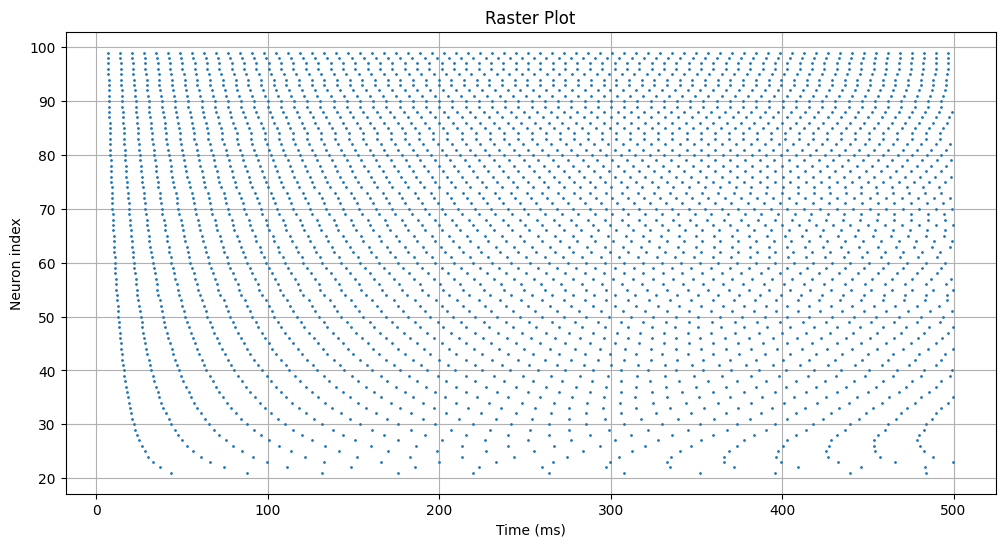

In [9]:
plt.figure(figsize=(12,6))

plt.plot(
    spikes.t/ms,
    spikes.i,
    '.',
    markersize=2
)

plt.xlabel("Time (ms)")
plt.ylabel("Neuron index")
plt.title("Raster Plot")

plt.grid()

plt.show()

In [10]:
start_scope()

N = 100

eqs = '''
dv/dt = (-(v + 70*mV) + (100*Mohm)*I)/(10*ms) : volt
I : amp
'''

G = NeuronGroup(
    N,
    eqs,
    threshold='v > -50*mV',
    reset='v = -70*mV',
    method='exact'
)

G.v = -70*mV
G.I = '150*pA + i/N*250*pA'

spikes = SpikeMonitor(G)
rate_monitor = PopulationRateMonitor(G)

run(500*ms)

INFO       width adjusted from 20. ms to 20.1 ms [brian2.monitors.ratemonitor.adjusted_width]


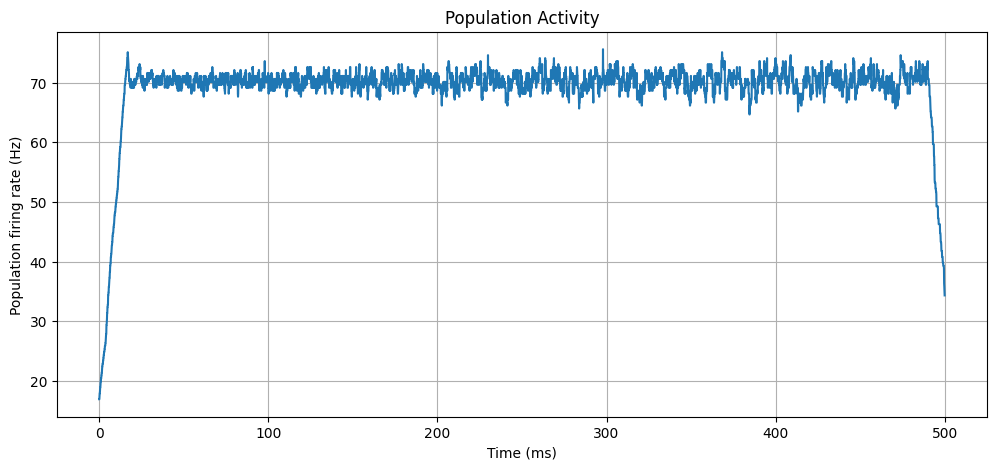

In [11]:
plt.figure(figsize=(12,5))

plt.plot(
    rate_monitor.t/ms,
    rate_monitor.smooth_rate(
        window='flat',
        width=20*ms
    )/Hz
)

plt.xlabel("Time (ms)")
plt.ylabel("Population firing rate (Hz)")
plt.title("Population Activity")

plt.grid()

plt.show()

In [12]:
currents = np.arange(100, 501, 25)

rates = []

for current in currents:

    start_scope()

    eqs = '''
    dv/dt = (-(v + 70*mV) + (100*Mohm)*I)/(10*ms) : volt
    I : amp
    '''

    G = NeuronGroup(
        1,
        eqs,
        threshold='v > -50*mV',
        reset='v = -70*mV',
        method='exact'
    )

    G.v = -70*mV
    G.I = current*pA

    S = SpikeMonitor(G)

    run(1*second)

    rates.append(S.count[0])

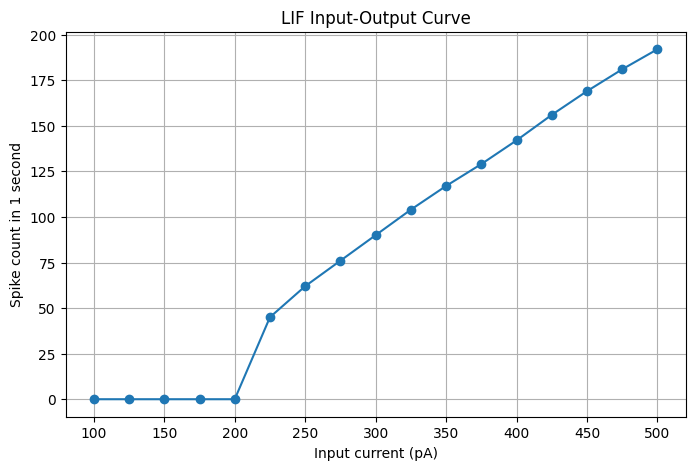

In [13]:
plt.figure(figsize=(8,5))

plt.plot(
    currents,
    rates,
    'o-'
)

plt.xlabel("Input current (pA)")
plt.ylabel("Spike count in 1 second")
plt.title("LIF Input-Output Curve")

plt.grid()

plt.show()

In [14]:
start_scope()

N = 20

eqs = '''
dv/dt = -v/(10*ms) : 1
'''

G = NeuronGroup(
    N,
    eqs,
    threshold='v > 1',
    reset='v = 0',
    method='exact'
)

# Synapses
S = Synapses(
    G,
    G,
    on_pre='v_post += 0.2'
)

S.connect(
    condition='i != j',
    p=0.1
)

G.v = 'i/N'

spikes = SpikeMonitor(G)

run(500*ms)

In [15]:
print("Neurons:", N)
print("Synapses:", len(S.i))

Neurons: 20
Synapses: 33


In [16]:
for i, j in zip(S.i[:10], S.j[:10]):
    print(i, "->", j)

0 -> 7
0 -> 15
1 -> 6
2 -> 8
3 -> 0
3 -> 12
4 -> 2
4 -> 14
5 -> 8
6 -> 13


In [17]:
x = np.random.rand(N)
y = np.random.rand(N)

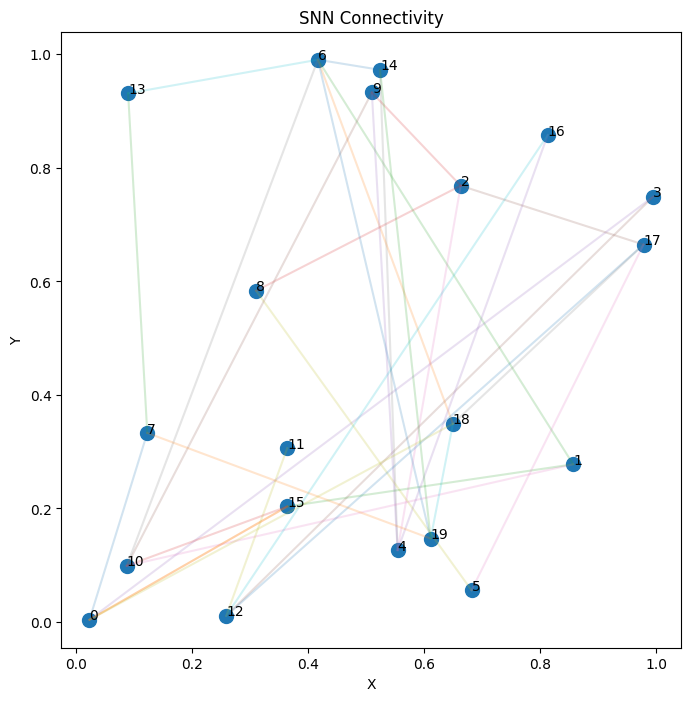

In [18]:
plt.figure(figsize=(8,8))

for i, j in zip(S.i[:], S.j[:]):

    plt.plot(
        [x[i], x[j]],
        [y[i], y[j]],
        alpha=0.2
    )

plt.scatter(
    x,
    y,
    s=100
)

for i in range(N):
    plt.text(
        x[i],
        y[i],
        str(i)
    )

plt.xlabel("X")
plt.ylabel("Y")
plt.title("SNN Connectivity")

plt.show()

In [19]:
start_scope()

N = 50

tau_m = 10*ms

eqs = '''
dv/dt = -v/tau_m : 1
'''

G = NeuronGroup(
    N,
    eqs,
    threshold='v > 1',
    reset='v = 0',
    method='exact'
)

G.v = 0

S = Synapses(
    G,
    G,

    '''
    w : 1

    dApre/dt = -Apre/taupre : 1 (event-driven)

    dApost/dt = -Apost/taupost : 1 (event-driven)
    ''',

    on_pre='''
    v_post += w

    Apre += dApre

    w = clip(w + Apost, 0, 1)
    ''',

    on_post='''
    Apost += dApost

    w = clip(w + Apre, 0, 1)
    '''
)

S.connect(
    condition='i != j',
    p=0.1
)

S.w = 0.2

taupre = 20*ms
taupost = 20*ms

dApre = 0.01
dApost = -0.012

spikes = SpikeMonitor(G)

weight_monitor = StateMonitor(
    S,
    'w',
    record=True
)

run(1*second)

WARNING    'i' is an internal variable of group 'synapses_1', but also exists in the run namespace with the value 19. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'j' is an internal variable of group 'synapses_1', but also exists in the run namespace with the value np.int32(14). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


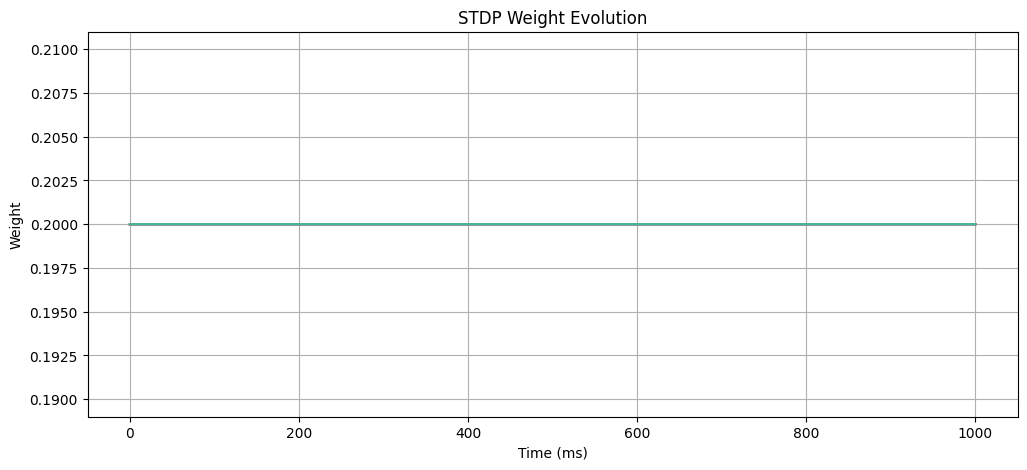

In [20]:
plt.figure(figsize=(12,5))

for i in range(min(10, len(S.w))):

    plt.plot(
        weight_monitor.t/ms,
        weight_monitor.w[i],
        alpha=0.7
    )

plt.xlabel("Time (ms)")
plt.ylabel("Weight")
plt.title("STDP Weight Evolution")

plt.grid()

plt.show()

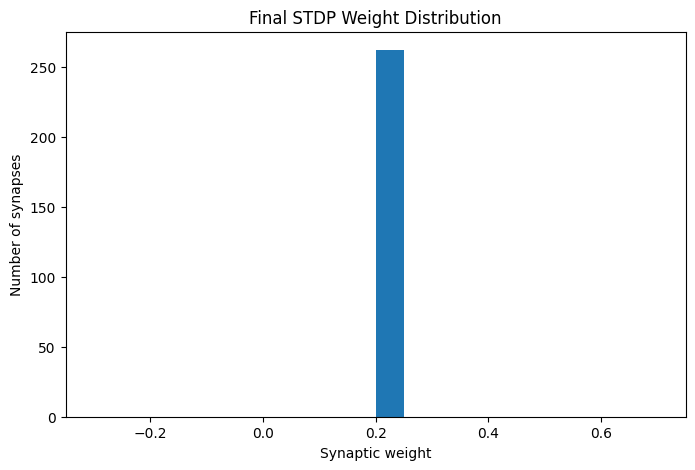

In [21]:
plt.figure(figsize=(8,5))

plt.hist(
    S.w[:],
    bins=20
)

plt.xlabel("Synaptic weight")
plt.ylabel("Number of synapses")
plt.title("Final STDP Weight Distribution")

plt.show()

In [22]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

In [23]:
eqs = '''
dv/dt = (
    I
    - gNa*m**3*h*(v - ENa)
    - gK*n**4*(v - EK)
    - gL*(v - EL)
) / C : volt

dm/dt = alpham*(1-m) - betam*m : 1
dn/dt = alphan*(1-n) - betan*n : 1
dh/dt = alphah*(1-h) - betah*h : 1

alpham = 0.1/mV * (v + 40*mV) /
         (1 - exp(-(v + 40*mV)/(10*mV))) / ms : Hz

betam = 4*exp(-(v + 65*mV)/(18*mV)) / ms : Hz

alphah = 0.07*exp(-(v + 65*mV)/(20*mV)) / ms : Hz

betah = 1 /
         (1 + exp(-(v + 35*mV)/(10*mV))) / ms : Hz

alphan = 0.01/mV * (v + 55*mV) /
         (1 - exp(-(v + 55*mV)/(10*mV))) / ms : Hz

betan = 0.125*exp(-(v + 65*mV)/(80*mV)) / ms : Hz

I : amp/meter**2
'''

In [24]:
C = 1*uF/cm**2

gNa = 120*msiemens/cm**2
gK  = 36*msiemens/cm**2
gL  = 0.3*msiemens/cm**2

ENa = 50*mV
EK  = -77*mV
EL  = -54.4*mV

In [25]:
G = NeuronGroup(
    1,
    eqs,
    method='exponential_euler'
)

In [26]:
G.v = -65*mV

G.m = 0.05
G.h = 0.6
G.n = 0.32

In [27]:
G.I = 10*uA/cm**2

In [28]:
M = StateMonitor(
    G,
    ['v', 'm', 'h', 'n'],
    record=True
)

In [29]:
run(100*ms)

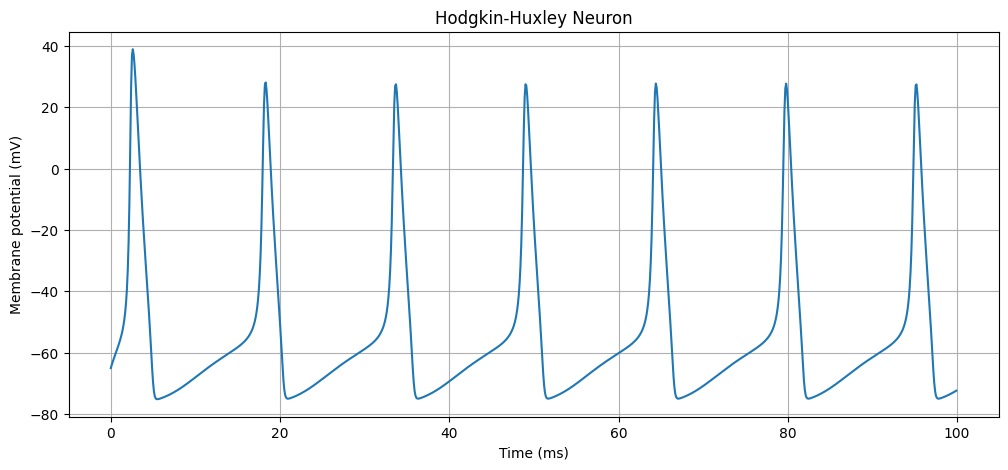

In [30]:
plt.figure(figsize=(12, 5))

plt.plot(
    M.t/ms,
    M.v[0]/mV
)

plt.xlabel("Time (ms)")
plt.ylabel("Membrane potential (mV)")
plt.title("Hodgkin-Huxley Neuron")

plt.grid()

plt.show()

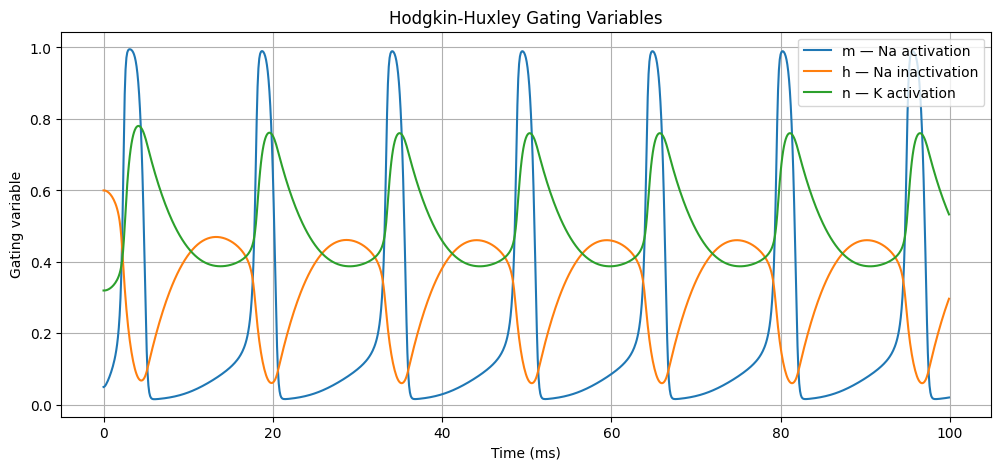

In [31]:
plt.figure(figsize=(12, 5))

plt.plot(
    M.t/ms,
    M.m[0],
    label='m — Na activation'
)

plt.plot(
    M.t/ms,
    M.h[0],
    label='h — Na inactivation'
)

plt.plot(
    M.t/ms,
    M.n[0],
    label='n — K activation'
)

plt.xlabel("Time (ms)")
plt.ylabel("Gating variable")
plt.title("Hodgkin-Huxley Gating Variables")

plt.legend()
plt.grid()

plt.show()

In [32]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

tau = 20*ms
EL = -70*mV
VT = -50*mV
DeltaT = 2*mV
R = 100*Mohm

eqs = '''
dv/dt = (
    -(v-EL)
    + DeltaT*exp((v-VT)/DeltaT)
    + R*I
)/tau : volt

I : amp
'''

G = NeuronGroup(
    1,
    eqs,
    threshold='v > -30*mV',
    reset='v = EL',
    method='euler'
)

G.v = EL
G.I = 250*pA

M = StateMonitor(G, 'v', record=True)
S = SpikeMonitor(G)

run(500*ms)

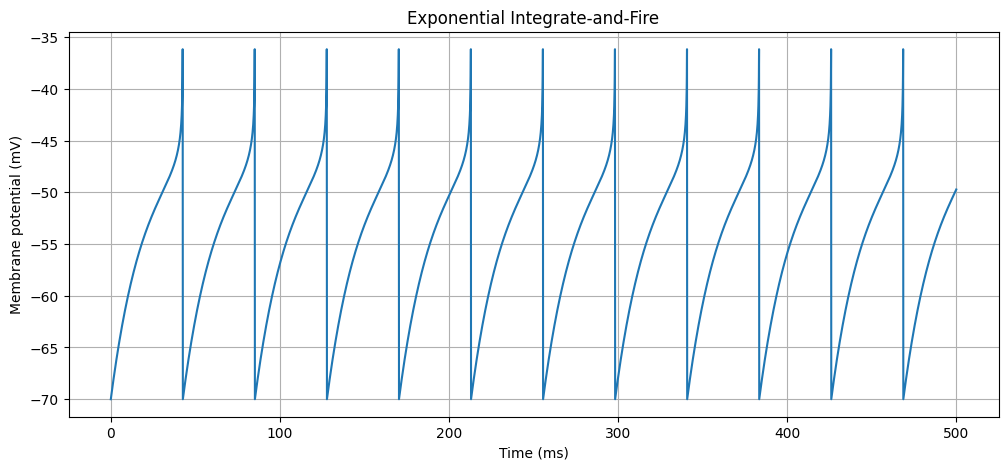

In [33]:
plt.figure(figsize=(12,5))

plt.plot(
    M.t/ms,
    M.v[0]/mV
)

plt.xlabel("Time (ms)")
plt.ylabel("Membrane potential (mV)")
plt.title("Exponential Integrate-and-Fire")

plt.grid()
plt.show()

In [34]:
start_scope()

eqs = '''
dv/dt = (
    -(v-EL)
    + DeltaT*exp((v-VT)/DeltaT)
    - R*w
    + R*I
)/tau_m : volt

dw/dt = (
    a*(v-EL)-w
)/tau_w : amp

I : amp
'''

tau_m = 20*ms
tau_w = 100*ms

EL = -70*mV
VT = -50*mV
DeltaT = 2*mV

R = 100*Mohm
a = 2*nS

G = NeuronGroup(
    1,
    eqs,
    threshold='v > -30*mV',
    reset='''
    v = EL
    w += 50*pA
    ''',
    method='euler'
)

G.v = EL
G.w = 0*pA
G.I = 250*pA

M = StateMonitor(
    G,
    ['v', 'w'],
    record=True
)

S = SpikeMonitor(G)

run(500*ms)

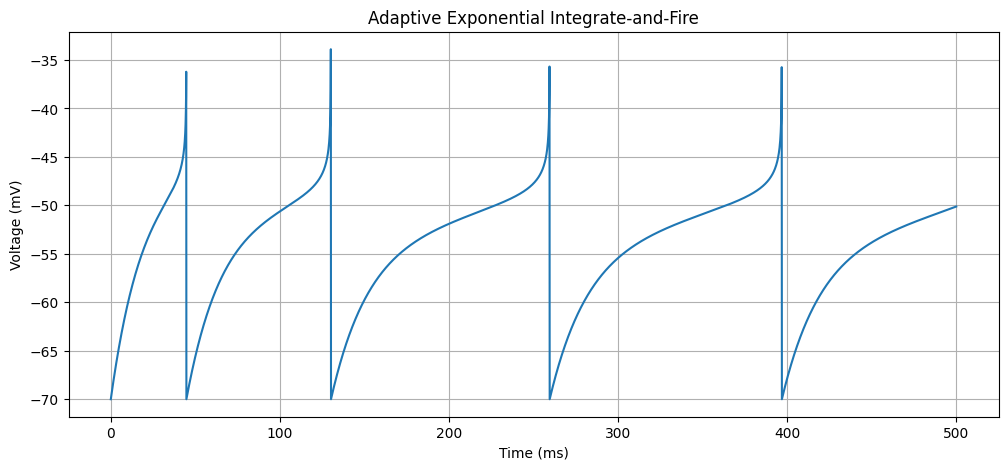

In [35]:
plt.figure(figsize=(12,5))

plt.plot(
    M.t/ms,
    M.v[0]/mV
)

plt.xlabel("Time (ms)")
plt.ylabel("Voltage (mV)")
plt.title("Adaptive Exponential Integrate-and-Fire")

plt.grid()
plt.show()

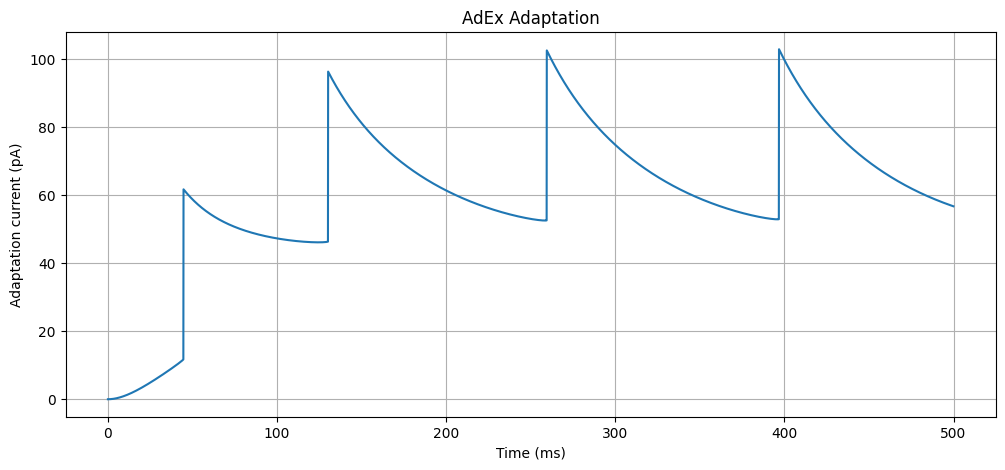

In [36]:
plt.figure(figsize=(12,5))

plt.plot(
    M.t/ms,
    M.w[0]/pA
)

plt.xlabel("Time (ms)")
plt.ylabel("Adaptation current (pA)")
plt.title("AdEx Adaptation")

plt.grid()
plt.show()

In [37]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

In [38]:
eqs = '''
dv/dt = (0.04*v**2 + 5*v + 140 - u + I)/ms : 1

du/dt = a*(b*v - u)/ms : 1

a : 1
b : 1
c : 1
d : 1
I : 1
'''

In [39]:
G = NeuronGroup(
    1,
    eqs,
    threshold='v >= 30',
    reset='''
    v = c
    u += d
    ''',
    method='euler'
)

In [40]:
G.v = -65
G.u = 0

G.a = 0.02
G.b = 0.2
G.c = -65
G.d = 8

G.I = 10

In [41]:
M = StateMonitor(
    G,
    ['v', 'u'],
    record=True
)

S = SpikeMonitor(G)

In [42]:
run(500*ms)

WARNING    'a' is an internal variable of group 'neurongroup', but also exists in the run namespace with the value 2. * nsiemens. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


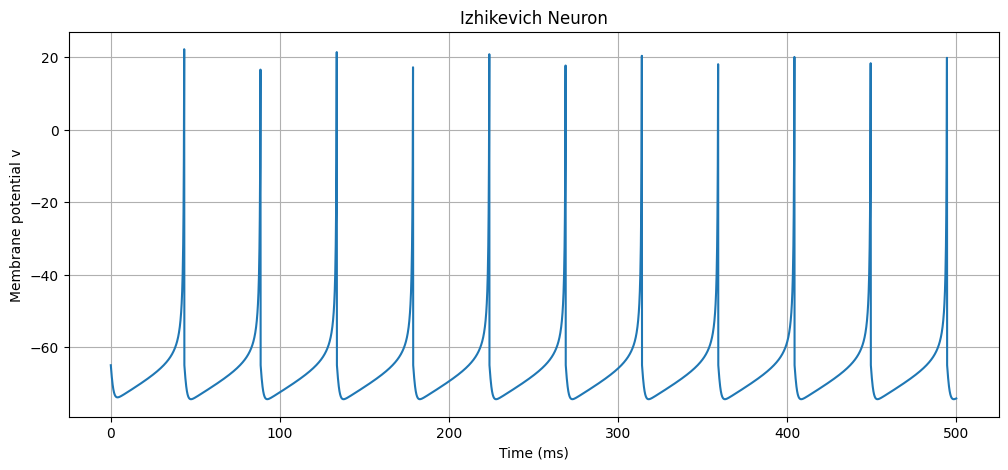

In [43]:
plt.figure(figsize=(12, 5))

plt.plot(
    M.t/ms,
    M.v[0]
)

plt.xlabel("Time (ms)")
plt.ylabel("Membrane potential v")
plt.title("Izhikevich Neuron")

plt.grid()
plt.show()

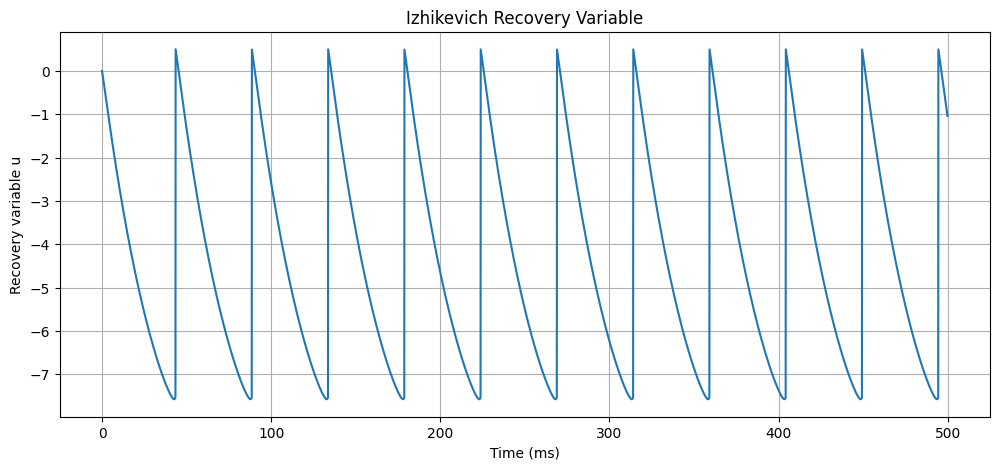

In [44]:
plt.figure(figsize=(12, 5))

plt.plot(
    M.t/ms,
    M.u[0]
)

plt.xlabel("Time (ms)")
plt.ylabel("Recovery variable u")
plt.title("Izhikevich Recovery Variable")

plt.grid()
plt.show()

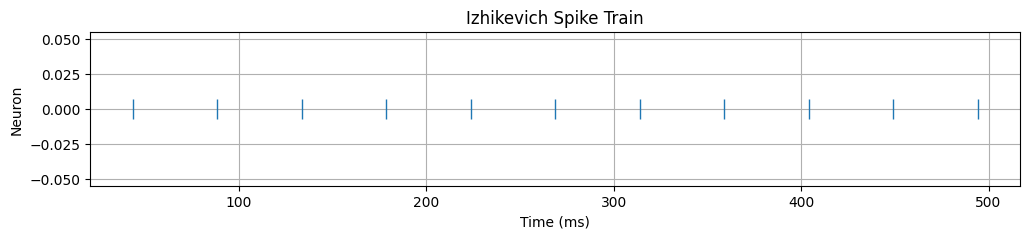

In [45]:
plt.figure(figsize=(12, 2))

plt.plot(
    S.t/ms,
    S.i,
    '|',
    markersize=15
)

plt.xlabel("Time (ms)")
plt.ylabel("Neuron")
plt.title("Izhikevich Spike Train")

plt.grid()
plt.show()

In [46]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

In [47]:
eqs = '''
dv/dt = (v - v**3/3 - w + I) / tau : 1

dw/dt = epsilon*(v + a - b*w) / tau : 1

I : 1
'''

In [48]:
tau = 10*ms

epsilon = 0.08
a = 0.7
b = 0.8

In [49]:
input_current = 0.2

In [50]:
G = NeuronGroup(
    1,
    eqs,
    method='euler'
)

In [51]:
G.v = -1
G.w = 1
G.I = input_current

In [52]:
M = StateMonitor(
    G,
    ['v', 'w'],
    record=True
)

In [53]:
run(500*ms)

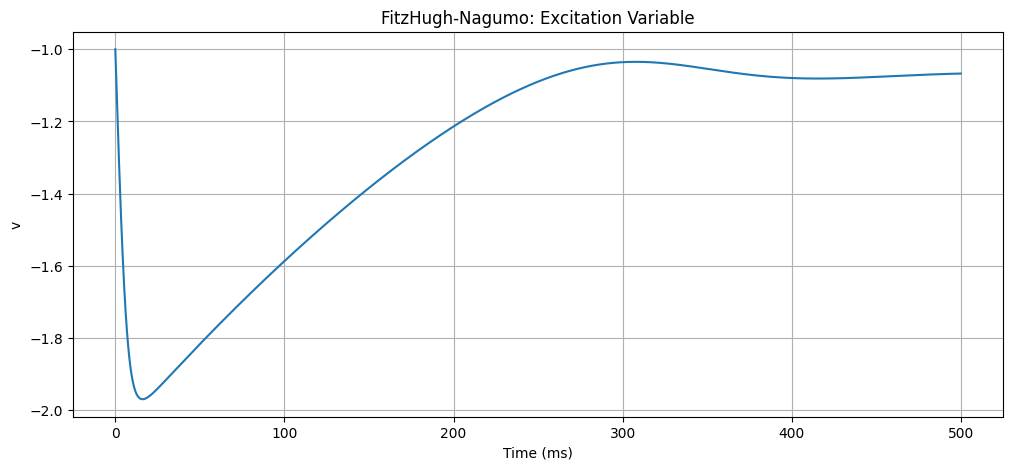

In [54]:
plt.figure(figsize=(12, 5))

plt.plot(
    M.t/ms,
    M.v[0]
)

plt.xlabel("Time (ms)")
plt.ylabel("v")
plt.title("FitzHugh-Nagumo: Excitation Variable")

plt.grid()
plt.show()

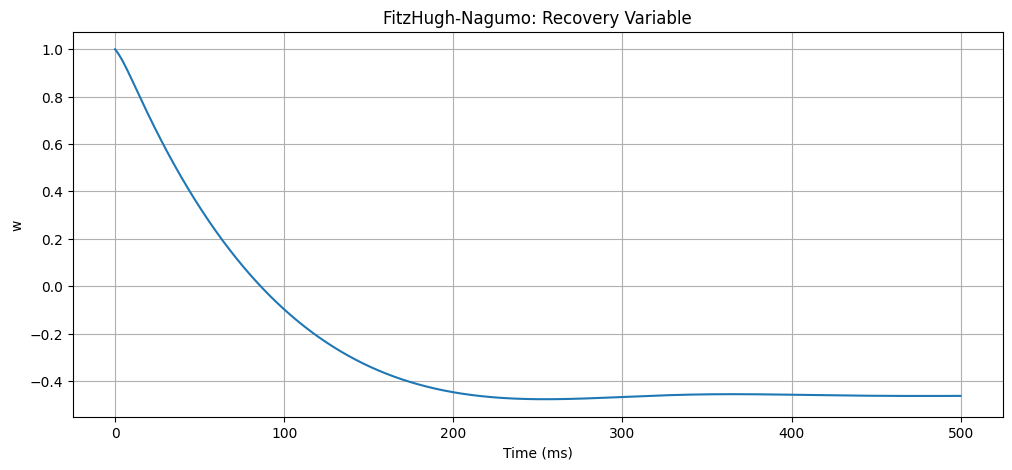

In [55]:
plt.figure(figsize=(12, 5))

plt.plot(
    M.t/ms,
    M.w[0]
)

plt.xlabel("Time (ms)")
plt.ylabel("w")
plt.title("FitzHugh-Nagumo: Recovery Variable")

plt.grid()
plt.show()

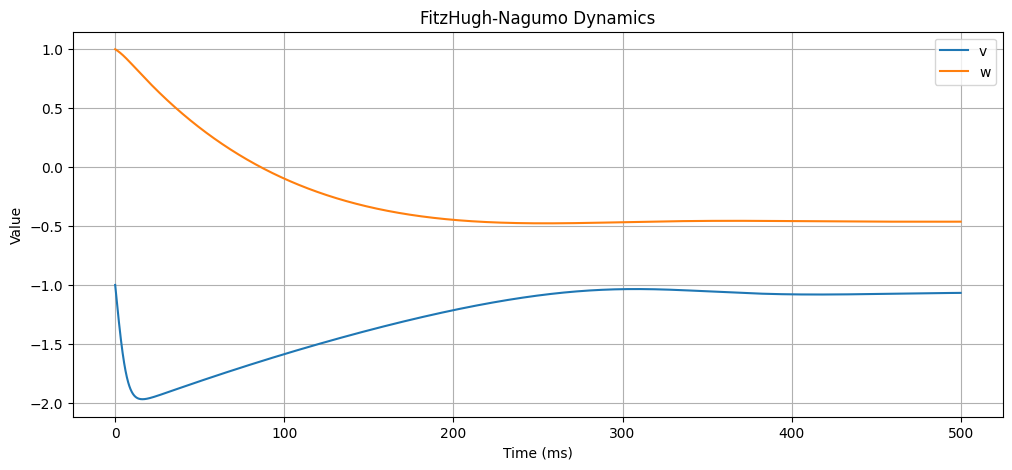

In [56]:
plt.figure(figsize=(12, 5))

plt.plot(
    M.t/ms,
    M.v[0],
    label='v'
)

plt.plot(
    M.t/ms,
    M.w[0],
    label='w'
)

plt.xlabel("Time (ms)")
plt.ylabel("Value")
plt.title("FitzHugh-Nagumo Dynamics")

plt.legend()
plt.grid()
plt.show()

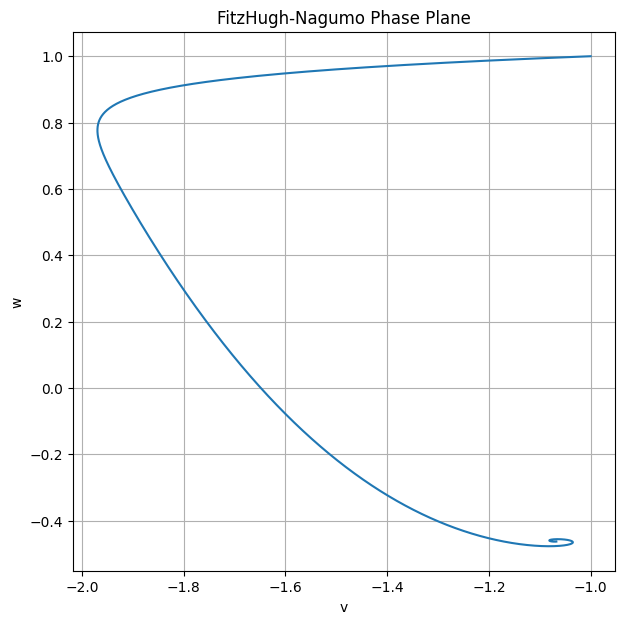

In [57]:
plt.figure(figsize=(7, 7))

plt.plot(
    M.v[0],
    M.w[0]
)

plt.xlabel("v")
plt.ylabel("w")
plt.title("FitzHugh-Nagumo Phase Plane")

plt.grid()
plt.show()

In [58]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

In [59]:
eqs = '''
dv/dt = (
    I
    - gCa*m_inf*(v - ECa)
    - gK*w*(v - EK)
    - gL*(v - EL)
) / C : volt

dw/dt = (w_inf - w) / tau_w : 1

m_inf = 0.5*(1 + tanh((v - V1)/V2)) : 1

w_inf = 0.5*(1 + tanh((v - V3)/V4)) : 1

tau_w = 1 / (phi*cosh((v - V3)/(2*V4))) : second

I : amp/meter**2
'''

In [60]:
C = 20*uF/cm**2

gCa = 4*msiemens/cm**2
gK  = 8*msiemens/cm**2
gL  = 2*msiemens/cm**2

ECa = 120*mV
EK  = -84*mV
EL  = -60*mV

In [61]:
V1 = -1.2*mV
V2 = 18*mV

V3 = 2*mV
V4 = 30*mV

phi = 0.04/ms

In [62]:
G = NeuronGroup(
    1,
    eqs,
    method='exponential_euler'
)

In [63]:
G.v = -60*mV
G.w = 0

In [64]:
G.I = 80*uA/cm**2

In [65]:
M = StateMonitor(
    G,
    ['v', 'w', 'm_inf', 'w_inf'],
    record=True
)

In [66]:
run(500*ms)

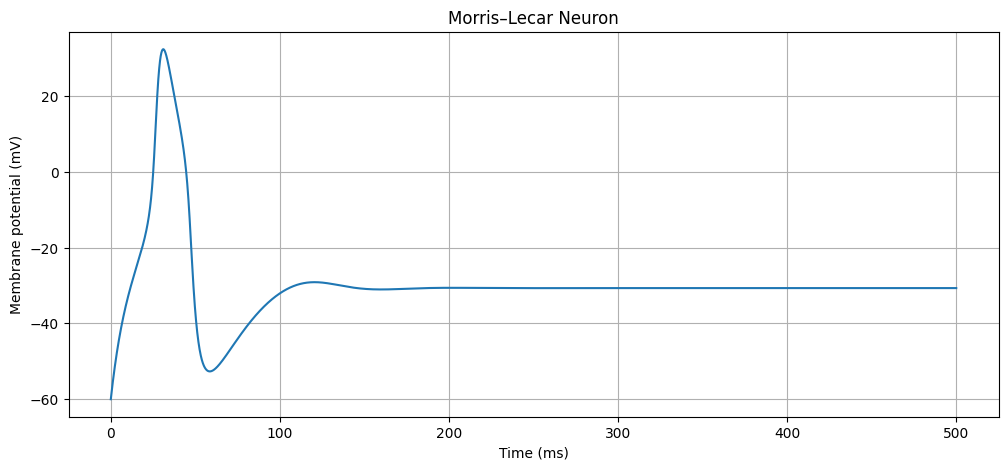

In [67]:
plt.figure(figsize=(12, 5))

plt.plot(
    M.t/ms,
    M.v[0]/mV
)

plt.xlabel("Time (ms)")
plt.ylabel("Membrane potential (mV)")
plt.title("Morris–Lecar Neuron")

plt.grid()
plt.show()

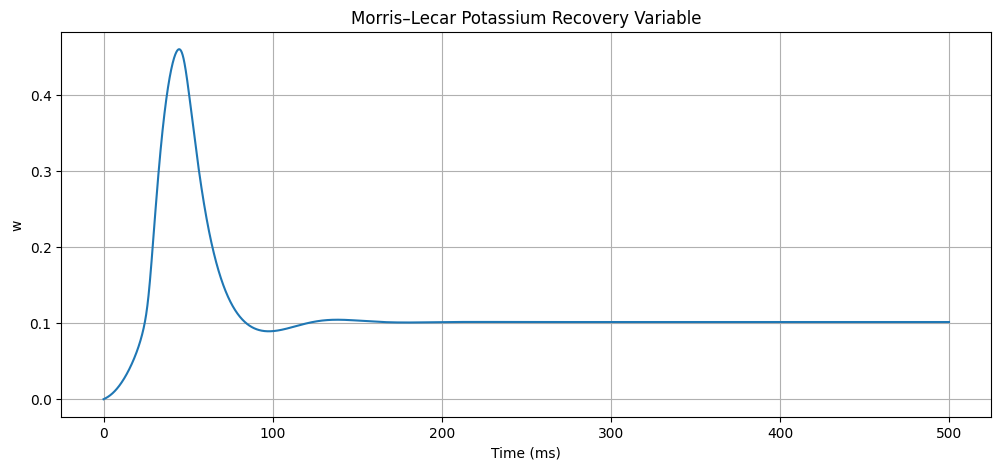

In [68]:
plt.figure(figsize=(12, 5))

plt.plot(
    M.t/ms,
    M.w[0]
)

plt.xlabel("Time (ms)")
plt.ylabel("w")
plt.title("Morris–Lecar Potassium Recovery Variable")

plt.grid()
plt.show()

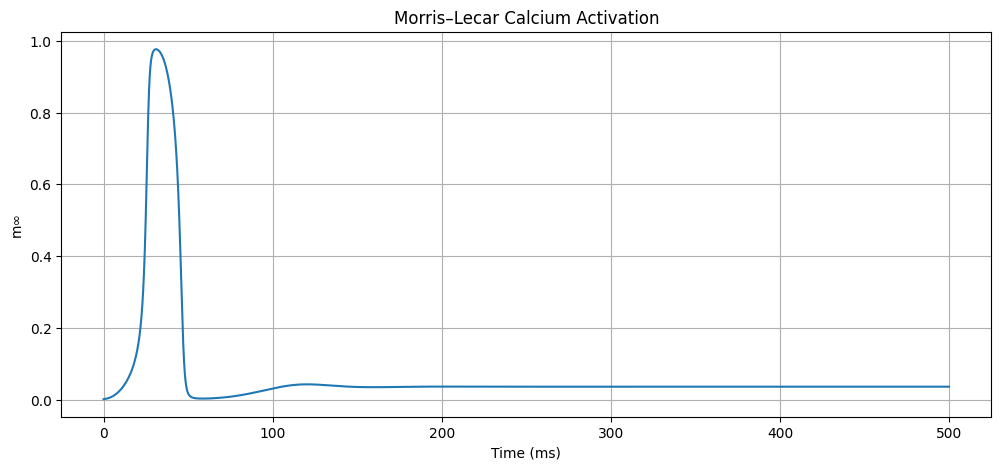

In [69]:
plt.figure(figsize=(12, 5))

plt.plot(
    M.t/ms,
    M.m_inf[0]
)

plt.xlabel("Time (ms)")
plt.ylabel("m∞")
plt.title("Morris–Lecar Calcium Activation")

plt.grid()
plt.show()

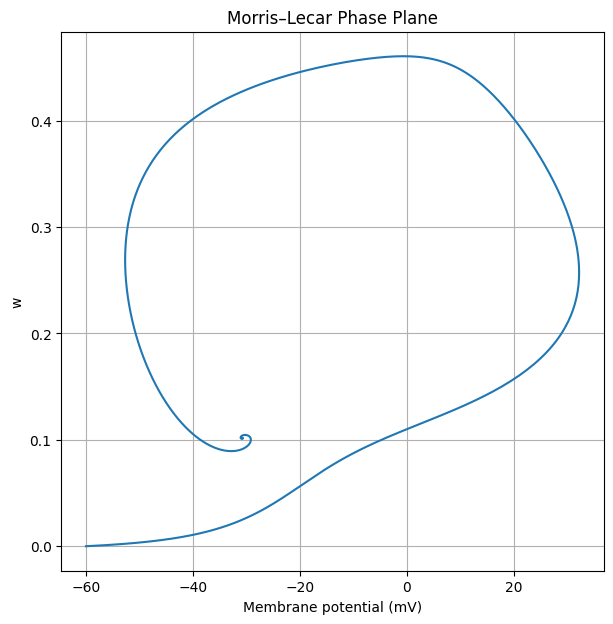

In [70]:
plt.figure(figsize=(7, 7))

plt.plot(
    M.v[0]/mV,
    M.w[0]
)

plt.xlabel("Membrane potential (mV)")
plt.ylabel("w")
plt.title("Morris–Lecar Phase Plane")

plt.grid()
plt.show()

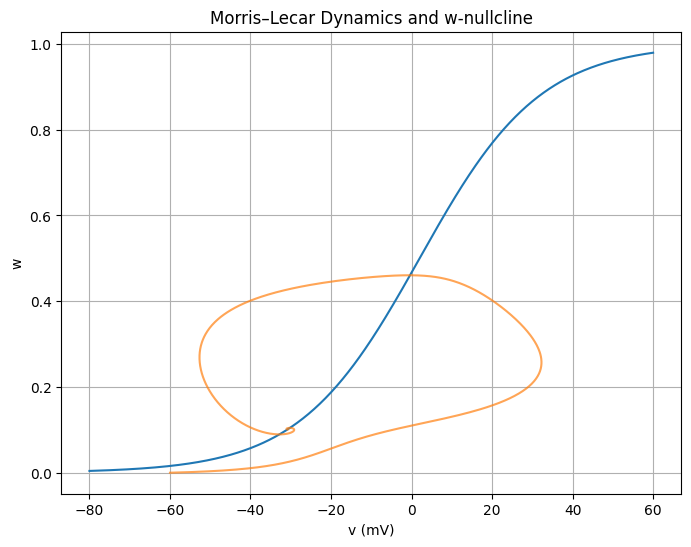

In [71]:
v_values = np.linspace(-80, 60, 500)*mV

w_values = 0.5 * (
    1 + np.tanh(
        (v_values - V3)/V4
    )
)

plt.figure(figsize=(8, 6))

plt.plot(
    v_values/mV,
    w_values
)

plt.plot(
    M.v[0]/mV,
    M.w[0],
    alpha=0.7
)

plt.xlabel("v (mV)")
plt.ylabel("w")
plt.title("Morris–Lecar Dynamics and w-nullcline")

plt.grid()
plt.show()

In [72]:
from brian2 import *
import matplotlib.pyplot as plt
import numpy as np

start_scope()

In [73]:
eqs = '''
dx/dt = (y - a*x**3 + b*x**2 - z + I) / tau : 1

dy/dt = (c - d*x**2 - y) / tau : 1

dz/dt = r*(s*(x - xR) - z) / tau : 1

I : 1
'''

In [74]:
tau = 1*ms

a = 1
b = 3

c = 1
d = 5

r = 0.005
s = 4

xR = -1.6

In [75]:
G = NeuronGroup(
    1,
    eqs,
    method='euler'
)

In [76]:
G.x = -1.3
G.y = -7
G.z = 3

In [77]:
G.I = 3.25

In [78]:
M = StateMonitor(
    G,
    ['x', 'y', 'z'],
    record=True
)

In [79]:
run(2000*ms)

WARNING    'x' is an internal variable of group 'neurongroup_3', but also exists in the run namespace with the value array([0.02374118, 0.85662622, 0.6629947 , ..., 0.97776997, 0.64957689,
       0.61122723]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'y' is an internal variable of group 'neurongroup_3', but also exists in the run namespace with the value array([0.00406775, 0.2778338 , 0.76861113, ..., 0.66488547, 0.34915797,
       0.14700348]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


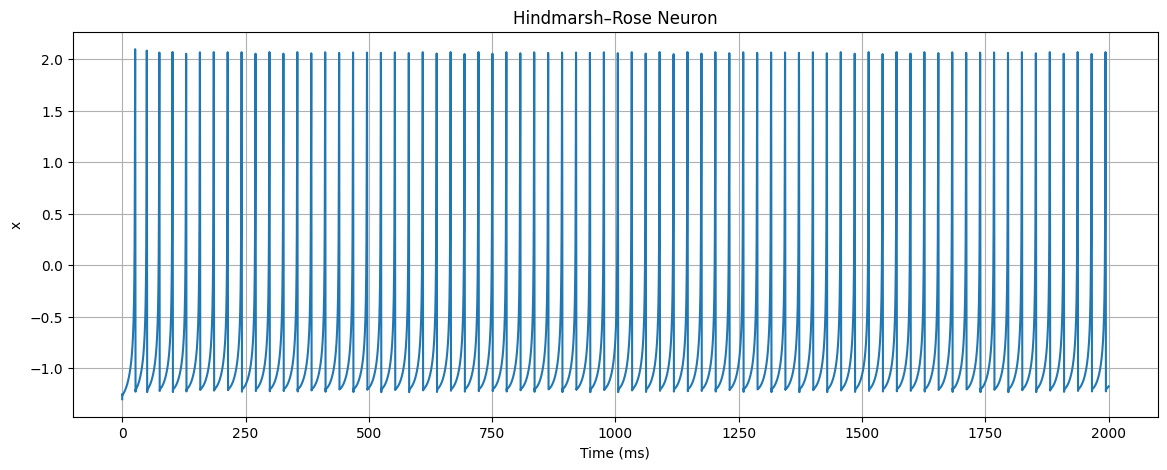

In [80]:
plt.figure(figsize=(14, 5))

plt.plot(
    M.t/ms,
    M.x[0]
)

plt.xlabel("Time (ms)")
plt.ylabel("x")
plt.title("Hindmarsh–Rose Neuron")

plt.grid()
plt.show()

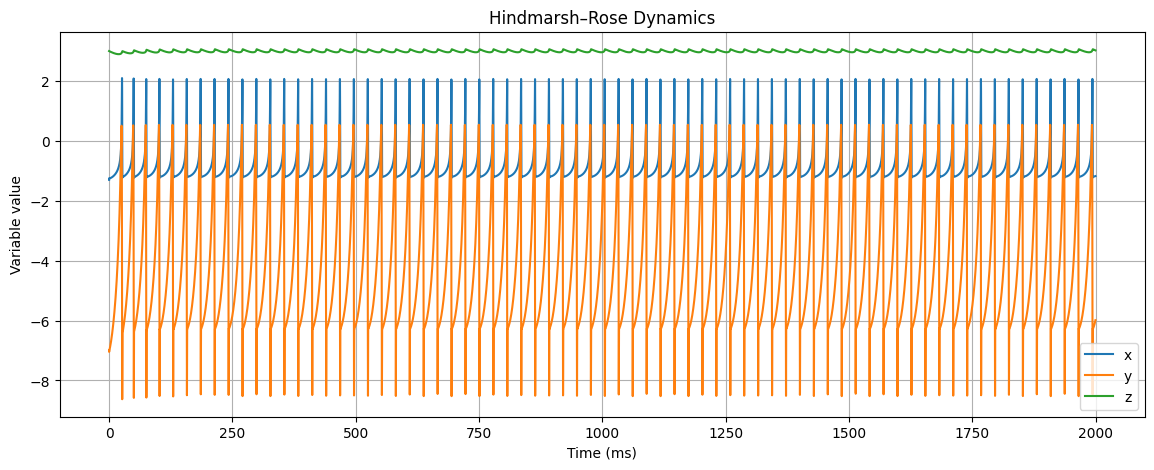

In [81]:
plt.figure(figsize=(14, 5))

plt.plot(
    M.t/ms,
    M.x[0],
    label='x'
)

plt.plot(
    M.t/ms,
    M.y[0],
    label='y'
)

plt.plot(
    M.t/ms,
    M.z[0],
    label='z'
)

plt.xlabel("Time (ms)")
plt.ylabel("Variable value")
plt.title("Hindmarsh–Rose Dynamics")

plt.legend()
plt.grid()
plt.show()

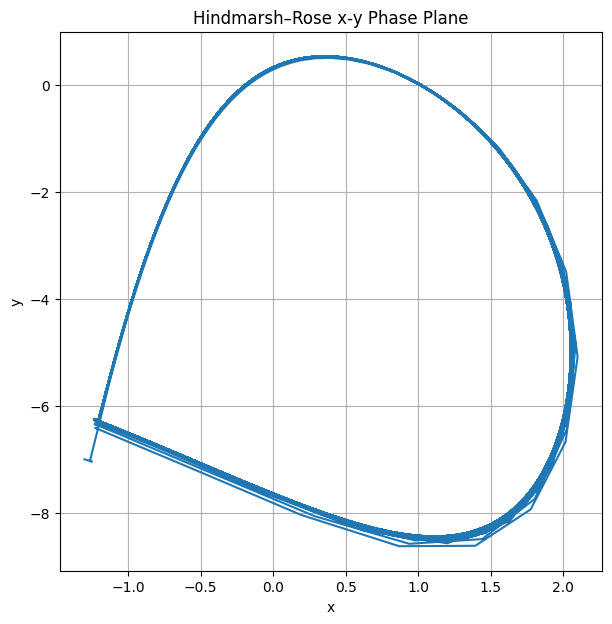

In [82]:
plt.figure(figsize=(7, 7))

plt.plot(
    M.x[0],
    M.y[0]
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Hindmarsh–Rose x-y Phase Plane")

plt.grid()
plt.show()

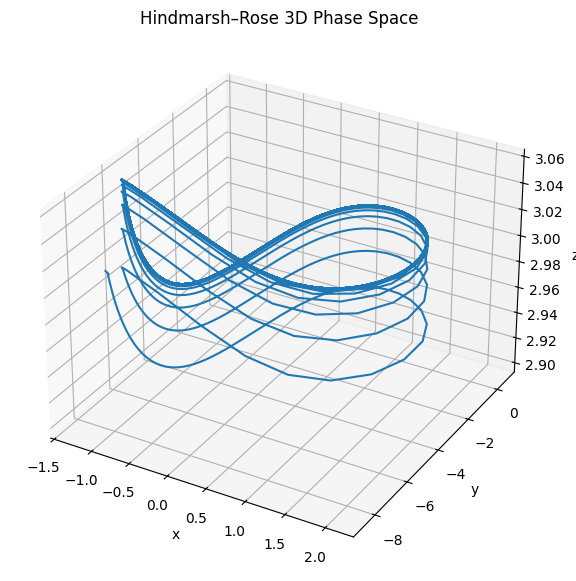

In [83]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(9, 7))

ax = fig.add_subplot(111, projection='3d')

ax.plot(
    M.x[0],
    M.y[0],
    M.z[0]
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

ax.set_title("Hindmarsh–Rose 3D Phase Space")

plt.show()

In [84]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

In [85]:
indices = [
    0, 0, 0,
    1, 1, 1,
    2, 2, 2
]

times = [
    10, 30, 50,
    20, 40, 60,
    15, 35, 55
] * ms

In [86]:
G = SpikeGeneratorGroup(
    3,
    indices=indices,
    times=times
)

In [87]:
S = SpikeMonitor(G)

In [88]:
run(100*ms)

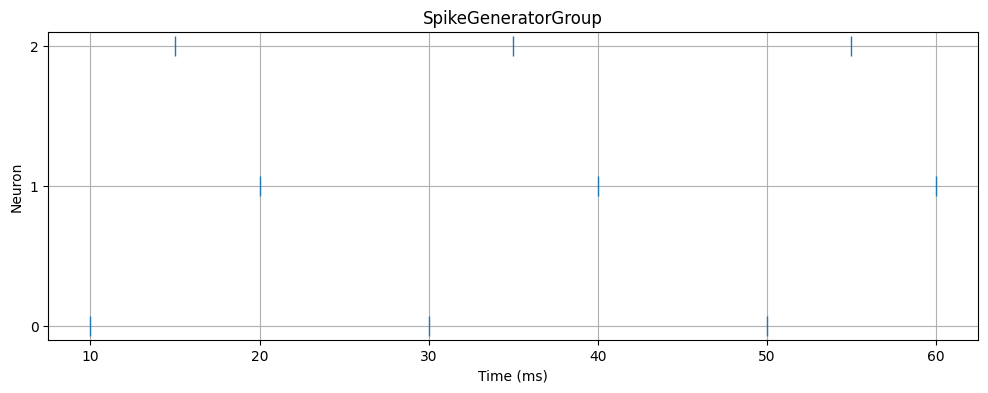

In [89]:
plt.figure(figsize=(12, 4))

plt.plot(
    S.t/ms,
    S.i,
    '|',
    markersize=15
)

plt.xlabel("Time (ms)")
plt.ylabel("Neuron")
plt.title("SpikeGeneratorGroup")

plt.yticks([0, 1, 2])

plt.grid()
plt.show()

In [90]:
start_scope()

indices = [
    0, 0, 0,
    1, 1, 1,
    2, 2, 2
]

times = [
    10, 30, 50,
    20, 40, 60,
    15, 35, 55
] * ms

input_group = SpikeGeneratorGroup(
    3,
    indices=indices,
    times=times
)

In [91]:
tau = 20*ms
EL = -70*mV
Vth = -50*mV

eqs = '''
dv/dt = (EL-v)/tau : volt
'''

In [92]:
output = NeuronGroup(
    1,
    eqs,
    threshold='v > Vth',
    reset='v = EL',
    method='exact'
)

output.v = EL

In [93]:
syn = Synapses(
    input_group,
    output,
    on_pre='v_post += 8*mV'
)

syn.connect()

In [94]:
M = StateMonitor(
    output,
    'v',
    record=True
)

S_in = SpikeMonitor(input_group)
S_out = SpikeMonitor(output)

In [95]:
run(100*ms)

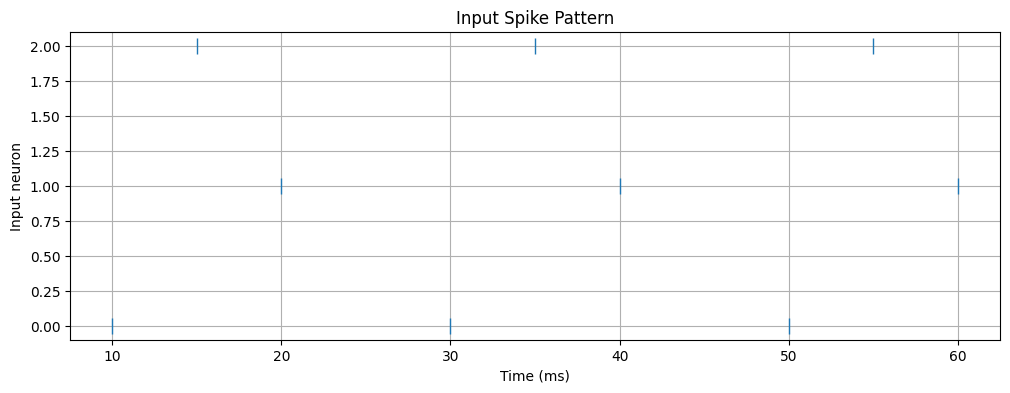

In [96]:
plt.figure(figsize=(12, 4))

plt.plot(
    S_in.t/ms,
    S_in.i,
    '|',
    markersize=12
)

plt.xlabel("Time (ms)")
plt.ylabel("Input neuron")
plt.title("Input Spike Pattern")

plt.grid()
plt.show()

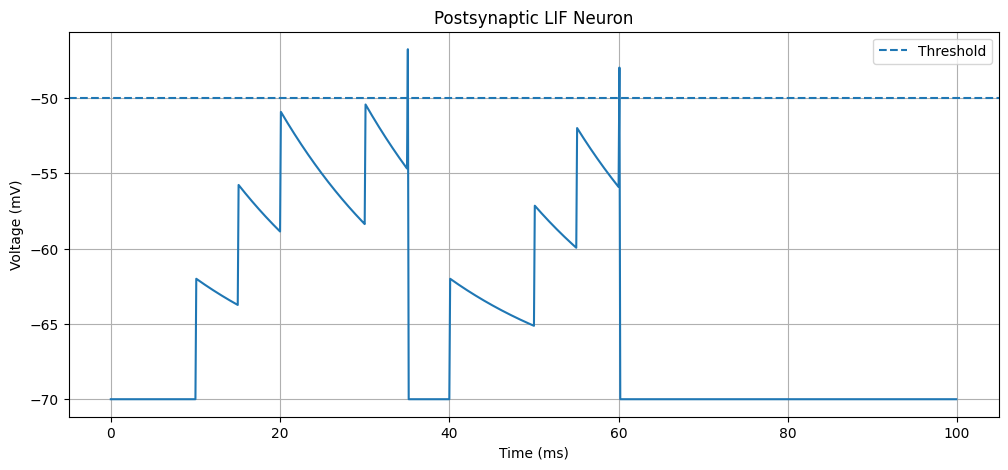

In [97]:
plt.figure(figsize=(12, 5))

plt.plot(
    M.t/ms,
    M.v[0]/mV
)

plt.axhline(
    Vth/mV,
    linestyle='--',
    label='Threshold'
)

plt.xlabel("Time (ms)")
plt.ylabel("Voltage (mV)")
plt.title("Postsynaptic LIF Neuron")

plt.legend()
plt.grid()
plt.show()

In [98]:
start_scope()

times = np.arange(0, 200, 20) * ms
indices = np.zeros(len(times), dtype=int)

G = SpikeGeneratorGroup(
    1,
    indices=indices,
    times=times
)

S = SpikeMonitor(G)

run(200*ms)

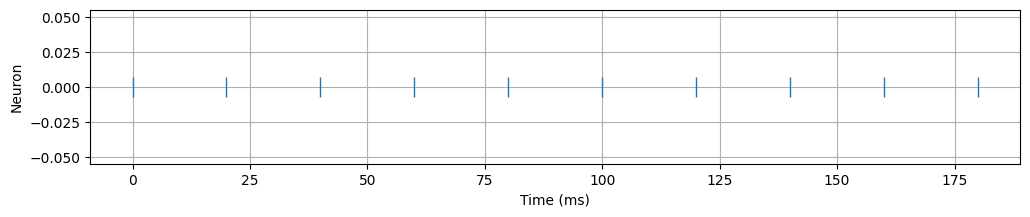

In [99]:
plt.figure(figsize=(12, 2))

plt.plot(
    S.t/ms,
    S.i,
    '|',
    markersize=15
)

plt.xlabel("Time (ms)")
plt.ylabel("Neuron")

plt.grid()
plt.show()

In [100]:
PoissonGroup(
    100,
    rates=20*Hz
)

PoissonGroup(100, rates=20. * hertz)

In [101]:
from brian2 import *
import matplotlib.pyplot as plt
import numpy as np

start_scope()

In [102]:
dt_input = 10*ms

input_values = np.array([
    0,
    0,
    0,
    0.5,
    0.5,
    0.5,
    0,
    0,
    1,
    1,
    1,
    0,
    0,
    0
]) * nA

I_timed = TimedArray(
    input_values,
    dt=dt_input
)

In [103]:
tau = 20*ms
EL = -70*mV
R = 100*Mohm

eqs = '''
dv/dt = (EL - v + R*I_timed(t)) / tau : volt
'''

In [104]:
G = NeuronGroup(
    1,
    eqs,
    threshold='v > -50*mV',
    reset='v = -70*mV',
    method='exact'
)

G.v = EL

In [105]:
M = StateMonitor(
    G,
    'v',
    record=True
)

S = SpikeMonitor(G)

In [106]:
run(140*ms)

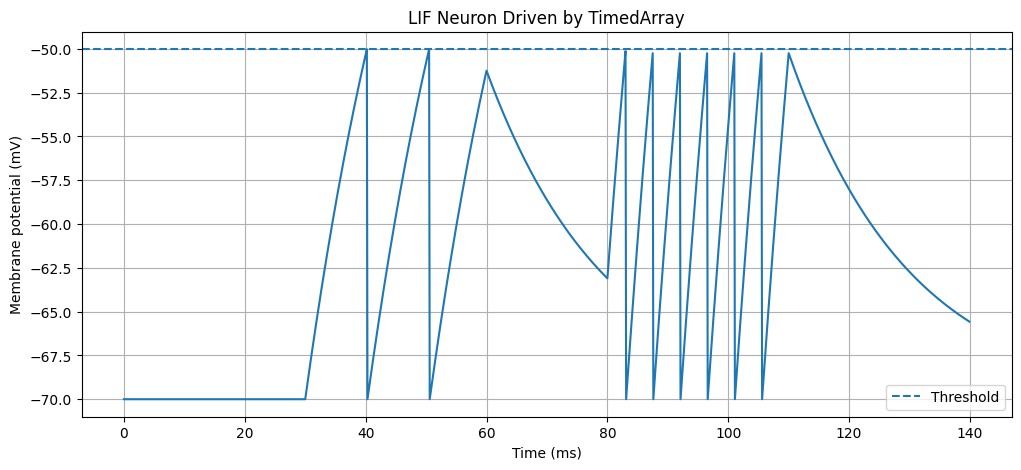

In [107]:
plt.figure(figsize=(12, 5))

plt.plot(
    M.t/ms,
    M.v[0]/mV
)

plt.axhline(
    -50,
    linestyle='--',
    label='Threshold'
)

plt.xlabel("Time (ms)")
plt.ylabel("Membrane potential (mV)")
plt.title("LIF Neuron Driven by TimedArray")

plt.legend()
plt.grid()
plt.show()

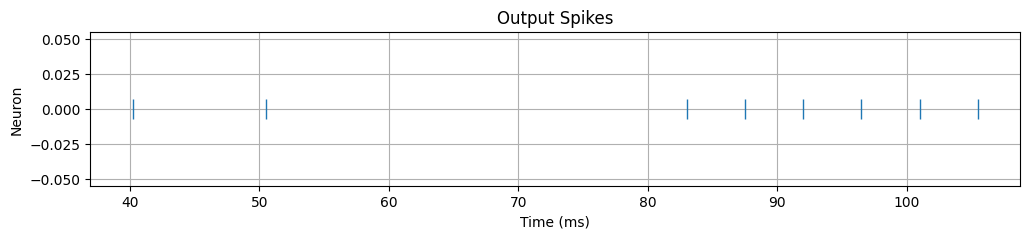

In [108]:
plt.figure(figsize=(12, 2))

plt.plot(
    S.t/ms,
    S.i,
    '|',
    markersize=15
)

plt.xlabel("Time (ms)")
plt.ylabel("Neuron")
plt.title("Output Spikes")

plt.grid()
plt.show()

In [109]:
start_scope()

duration = 500*ms
dt_input = 1*ms

t = np.arange(
    0,
    float(duration/ms),
    float(dt_input/ms)
) * ms

signal = (
    0.5 +
    0.5*np.sin(
        2*np.pi*5*(t/second)
    )
)

signal = signal * nA

I_timed = TimedArray(
    signal,
    dt=dt_input
)

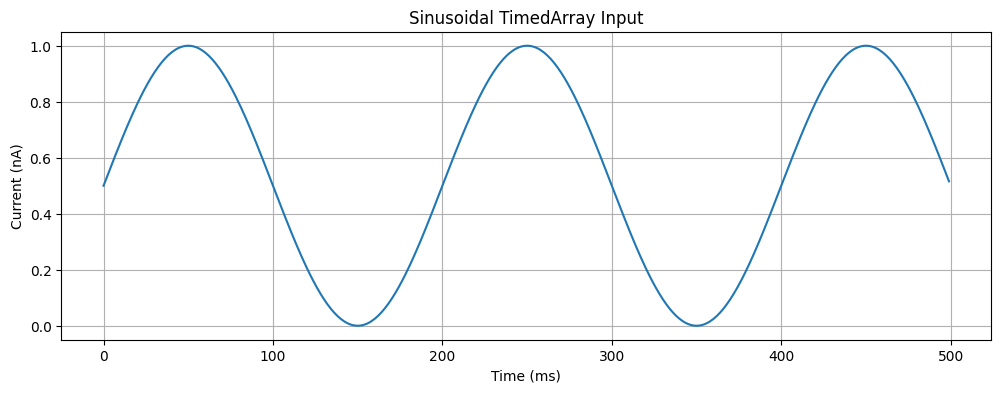

In [110]:
plt.figure(figsize=(12, 4))

plt.plot(
    t/ms,
    signal/nA
)

plt.xlabel("Time (ms)")
plt.ylabel("Current (nA)")
plt.title("Sinusoidal TimedArray Input")

plt.grid()
plt.show()

In [111]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

In [112]:
pre_times = [20, 40, 60, 80] * ms

pre_indices = [0, 0, 0, 0]

pre = SpikeGeneratorGroup(
    1,
    indices=pre_indices,
    times=pre_times
)

In [113]:
tau = 20*ms
EL = -70*mV
Vth = -50*mV
Vreset = -70*mV

eqs = '''
dv/dt = (EL - v) / tau : volt
'''

In [114]:
post = NeuronGroup(
    1,
    eqs,
    threshold='v > Vth',
    reset='v = Vreset',
    method='exact'
)

post.v = EL

In [115]:
syn = Synapses(
    pre,
    post,
    on_pre='v_post += 5*mV'
)

In [116]:
syn.connect()

In [117]:
M = StateMonitor(
    post,
    'v',
    record=True
)

S_pre = SpikeMonitor(pre)
S_post = SpikeMonitor(post)

In [118]:
run(100*ms)

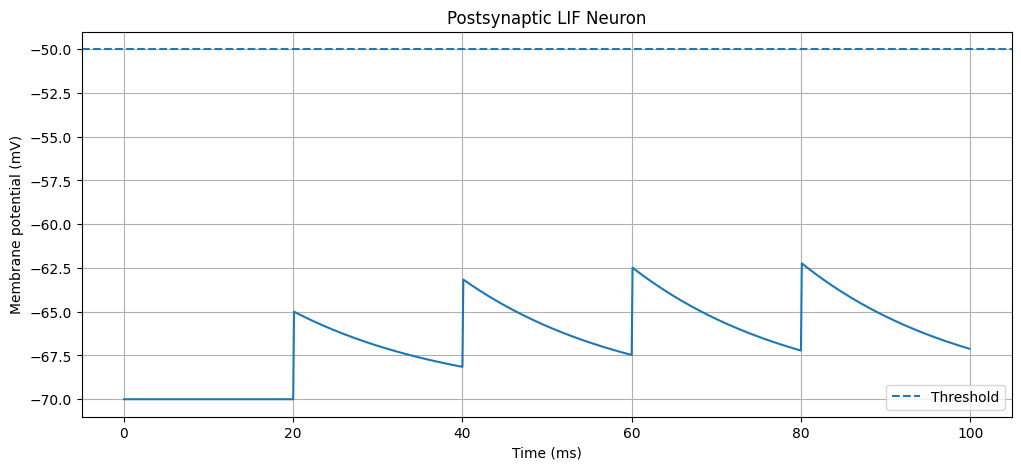

In [119]:
plt.figure(figsize=(12, 5))

plt.plot(
    M.t/ms,
    M.v[0]/mV
)

plt.axhline(
    Vth/mV,
    linestyle='--',
    label='Threshold'
)

plt.xlabel("Time (ms)")
plt.ylabel("Membrane potential (mV)")
plt.title("Postsynaptic LIF Neuron")

plt.legend()
plt.grid()
plt.show()

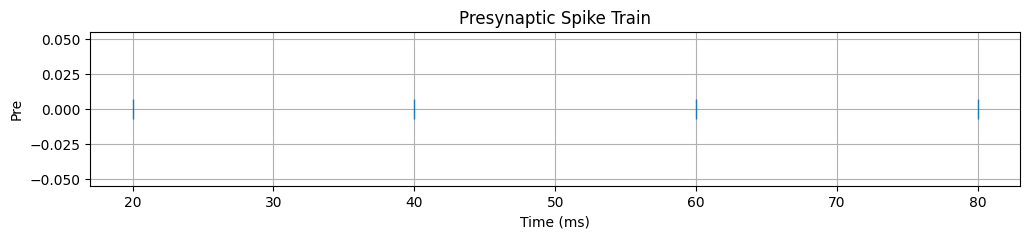

In [120]:
plt.figure(figsize=(12, 2))

plt.plot(
    S_pre.t/ms,
    S_pre.i,
    '|',
    markersize=15
)

plt.xlabel("Time (ms)")
plt.ylabel("Pre")
plt.title("Presynaptic Spike Train")

plt.grid()
plt.show()

In [121]:
syn_exc = Synapses(
    pre,
    post,
    on_pre='v_post += 5*mV'
)

syn_exc.connect()

In [122]:
syn_inh = Synapses(
    pre,
    post,
    on_pre='v_post -= 5*mV'
)

syn_inh.connect()

In [123]:
syn = Synapses(
    pre,
    post,
    '''
    w : volt
    ''',
    on_pre='v_post += w'
)

In [124]:
syn.connect()

syn.w = 5*mV

WARNING    The object 'synapses_4' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/469497763.py', line 1, in <cell line: 0>
    syn = Synapses( [brian2.core.base.unused_brian_object]


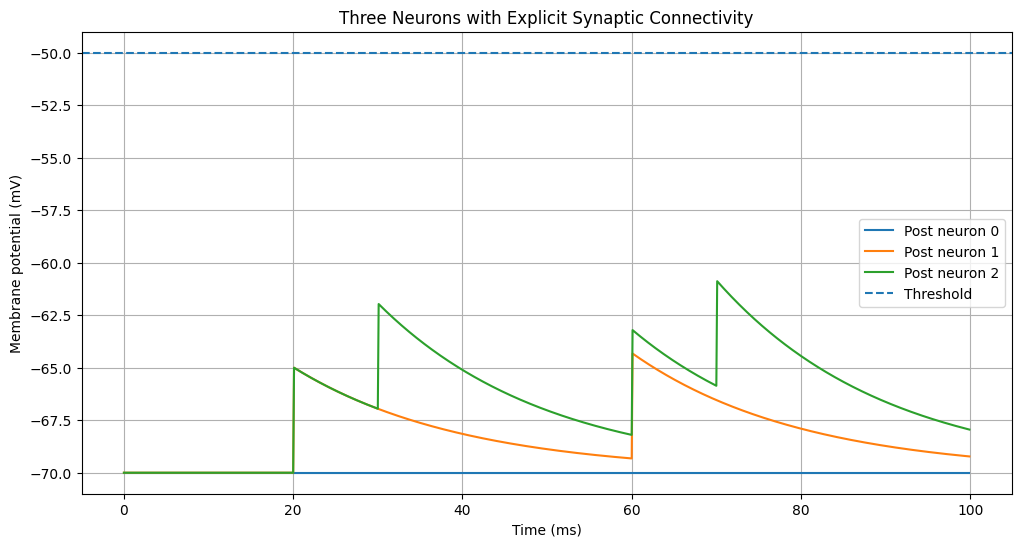

In [125]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

# =====================================================
# PRESYNAPTIC GROUP
# =====================================================

pre = SpikeGeneratorGroup(
    3,
    indices=[
        0, 0,
        1, 1,
        2, 2
    ],
    times=[
        20, 60,
        30, 70,
        40, 80
    ] * ms
)


# =====================================================
# POSTSYNAPTIC GROUP
# =====================================================

tau = 20*ms
EL = -70*mV
Vth = -50*mV
Vreset = -70*mV

eqs = '''
dv/dt = (EL-v)/tau : volt
'''

post = NeuronGroup(
    3,
    eqs,
    threshold='v > Vth',
    reset='v = Vreset',
    method='exact'
)

post.v = EL


# =====================================================
# SYNAPSES
# =====================================================

syn = Synapses(
    pre,
    post,
    '''
    w : volt
    ''',
    on_pre='v_post += w'
)


# =====================================================
# CONNECTIVITY
# =====================================================

syn.connect(
    i=[0, 0, 1],
    j=[1, 2, 2]
)

syn.w = 5*mV


# =====================================================
# MONITORS
# =====================================================

M = StateMonitor(
    post,
    'v',
    record=True
)

S_pre = SpikeMonitor(pre)
S_post = SpikeMonitor(post)


# =====================================================
# SIMULATION
# =====================================================

run(100*ms)


# =====================================================
# PLOT POSTSYNAPTIC VOLTAGES
# =====================================================

plt.figure(figsize=(12, 6))

for i in range(3):
    plt.plot(
        M.t/ms,
        M.v[i]/mV,
        label=f'Post neuron {i}'
    )

plt.axhline(
    Vth/mV,
    linestyle='--',
    label='Threshold'
)

plt.xlabel("Time (ms)")
plt.ylabel("Membrane potential (mV)")
plt.title("Three Neurons with Explicit Synaptic Connectivity")

plt.legend()
plt.grid()
plt.show()

In [126]:
syn.connect(
    p=0.2
)

In [127]:
syn.delay = 5*ms

In [128]:
syn.connect(
    i=0,
    j=[1, 2]
)

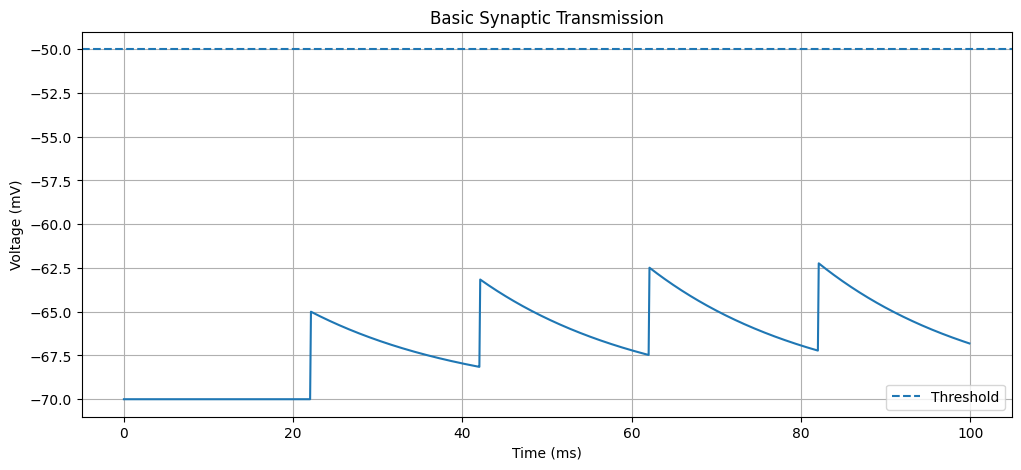

In [129]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

# -------------------------
# Presynaptic neuron
# -------------------------

pre = SpikeGeneratorGroup(
    1,
    indices=[0, 0, 0, 0],
    times=[20, 40, 60, 80]*ms
)

# -------------------------
# Postsynaptic LIF neuron
# -------------------------

tau = 20*ms
EL = -70*mV
Vth = -50*mV

eqs = '''
dv/dt = (EL-v)/tau : volt
'''

post = NeuronGroup(
    1,
    eqs,
    threshold='v > Vth',
    reset='v = EL',
    method='exact'
)

post.v = EL

# -------------------------
# Synapse
# -------------------------

syn = Synapses(
    pre,
    post,
    '''
    w : volt
    ''',
    on_pre='v_post += w'
)

syn.connect()
syn.w = 5*mV
syn.delay = 2*ms

# -------------------------
# Monitors
# -------------------------

M = StateMonitor(
    post,
    'v',
    record=True
)

S_pre = SpikeMonitor(pre)
S_post = SpikeMonitor(post)

# -------------------------
# Simulation
# -------------------------

run(100*ms)

# -------------------------
# Plot
# -------------------------

plt.figure(figsize=(12,5))

plt.plot(
    M.t/ms,
    M.v[0]/mV
)

plt.axhline(
    Vth/mV,
    linestyle='--',
    label='Threshold'
)

plt.xlabel("Time (ms)")
plt.ylabel("Voltage (mV)")
plt.title("Basic Synaptic Transmission")

plt.legend()
plt.grid()
plt.show()

In [130]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

In [131]:
pre = SpikeGeneratorGroup(
    3,
    indices=[
        0, 0,
        1, 1,
        2, 2
    ],
    times=[
        20, 60,
        30, 70,
        40, 80
    ] * ms
)

In [132]:
tau = 20*ms
EL = -70*mV
Vth = -50*mV
Vreset = -70*mV

eqs = '''
dv/dt = (EL - v + R*I_syn) / tau : volt
I_syn : amp
'''

R = 100*Mohm

post = NeuronGroup(
    3,
    eqs,
    threshold='v > Vth',
    reset='v = Vreset',
    method='euler'
)

post.v = EL

In [133]:
syn = Synapses(
    pre,
    post,
    '''
    w : amp
    ''',
    on_pre='I_syn_post += w'
)

In [134]:
syn.connect(
    i=[0, 0, 1],
    j=[1, 2, 2]
)

In [135]:
syn.w = 0.5*nA

In [136]:
M = StateMonitor(
    post,
    'v',
    record=True
)

S_pre = SpikeMonitor(pre)
S_post = SpikeMonitor(post)

In [137]:
run(100*ms)

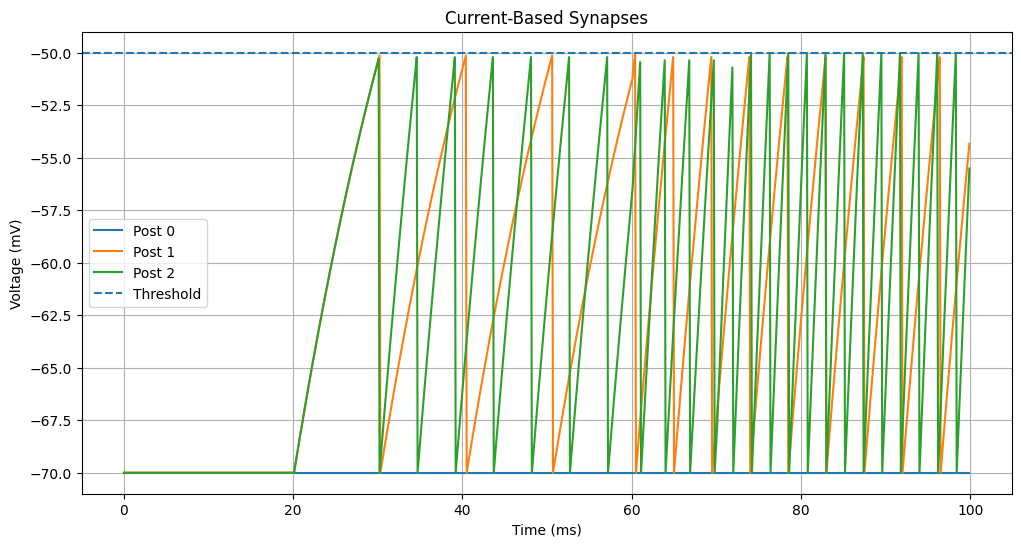

In [138]:
plt.figure(figsize=(12, 6))

for i in range(3):
    plt.plot(
        M.t/ms,
        M.v[i]/mV,
        label=f'Post {i}'
    )

plt.axhline(
    Vth/mV,
    linestyle='--',
    label='Threshold'
)

plt.xlabel("Time (ms)")
plt.ylabel("Voltage (mV)")
plt.title("Current-Based Synapses")

plt.legend()
plt.grid()
plt.show()

In [139]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

In [140]:
pre = SpikeGeneratorGroup(
    3,
    indices=[
        0, 0,
        1, 1,
        2, 2
    ],
    times=[
        20, 60,
        30, 70,
        40, 80
    ] * ms
)

In [141]:
C = 200*pF

gL = 10*nS
EL = -70*mV

Vth = -50*mV
Vreset = -70*mV

E_syn = 0*mV
tau_syn = 5*ms

In [142]:
eqs = '''
dv/dt = (gL*(EL-v) + I_syn) / C : volt

I_syn = g_syn*(E_syn-v) : amp

dg_syn/dt = -g_syn/tau_syn : siemens
'''

In [143]:
post = NeuronGroup(
    3,
    eqs,
    threshold='v > Vth',
    reset='v = Vreset',
    method='euler'
)

post.v = EL
post.g_syn = 0*nS

In [144]:
syn = Synapses(
    pre,
    post,
    '''
    w : siemens
    ''',
    on_pre='g_syn_post += w'
)

In [145]:
syn.connect(
    i=[0, 0, 1],
    j=[1, 2, 2]
)

In [146]:
syn.w = 5*nS

In [147]:
syn.delay = 2*ms

In [148]:
M = StateMonitor(
    post,
    ['v', 'g_syn'],
    record=True
)

S_pre = SpikeMonitor(pre)
S_post = SpikeMonitor(post)

In [149]:
run(100*ms)

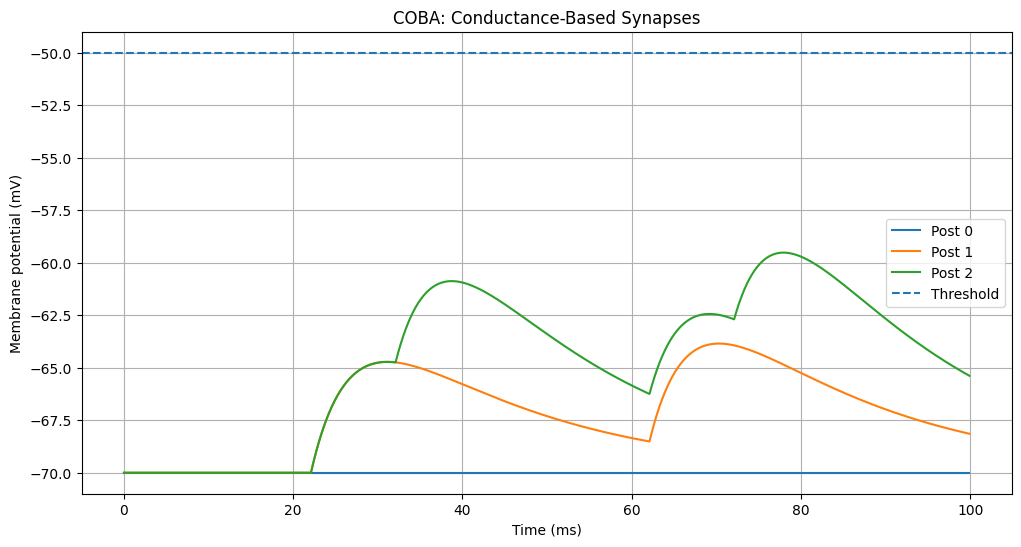

In [150]:
plt.figure(figsize=(12, 6))

for i in range(3):
    plt.plot(
        M.t/ms,
        M.v[i]/mV,
        label=f'Post {i}'
    )

plt.axhline(
    Vth/mV,
    linestyle='--',
    label='Threshold'
)

plt.xlabel("Time (ms)")
plt.ylabel("Membrane potential (mV)")
plt.title("COBA: Conductance-Based Synapses")

plt.legend()
plt.grid()
plt.show()

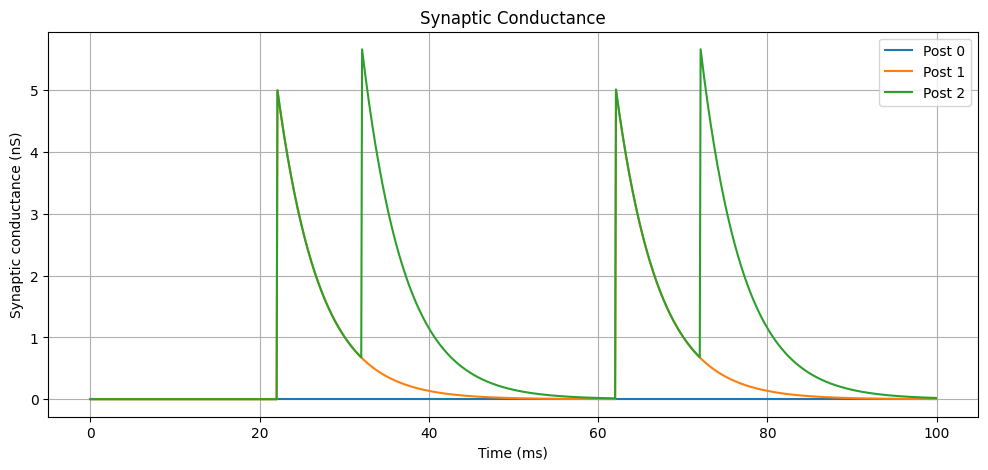

In [151]:
plt.figure(figsize=(12, 5))

for i in range(3):
    plt.plot(
        M.t/ms,
        M.g_syn[i]/nS,
        label=f'Post {i}'
    )

plt.xlabel("Time (ms)")
plt.ylabel("Synaptic conductance (nS)")
plt.title("Synaptic Conductance")

plt.legend()
plt.grid()
plt.show()

In [152]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

In [153]:
pre = SpikeGeneratorGroup(
    3,
    indices=[
        0, 0,
        1, 1,
        2, 2
    ],
    times=[
        10, 50,
        20, 60,
        30, 70
    ] * ms
)

In [154]:
C = 200*pF
gL = 10*nS

EL = -70*mV
Vth = -50*mV
Vreset = -70*mV

E_syn = 0*mV
tau_syn = 5*ms

In [155]:
eqs = '''
dv/dt = (gL*(EL-v) + I_syn) / C : volt

I_syn = g_syn*(E_syn-v) : amp

dg_syn/dt = -g_syn/tau_syn : siemens
'''

In [156]:
post = NeuronGroup(
    3,
    eqs,
    threshold='v > Vth',
    reset='v = Vreset',
    method='euler'
)

post.v = EL
post.g_syn = 0*nS

In [157]:
syn = Synapses(
    pre,
    post,
    '''
    w : siemens
    ''',
    on_pre='''
    g_syn_post += w
    '''
)

In [158]:
syn.connect(
    i=[0, 0, 1],
    j=[1, 2, 2]
)

In [159]:
syn.w = [2, 5, 10] * nS

In [160]:
print(syn.w[:])

[ 2.  5. 10.] nS


In [161]:
print("Pre indices :", syn.i[:])
print("Post indices:", syn.j[:])

Pre indices : [0 0 1]
Post indices: [1 2 2]


In [162]:
SM = StateMonitor(
    syn,
    'w',
    record=True
)

In [163]:
tau_w = 100*ms

In [164]:
syn = Synapses(
    pre,
    post,
    '''
    w : siemens
    ''',
    on_pre='''
    g_syn_post += w
    '''
)

In [165]:
syn = Synapses(
    pre,
    post,
    '''
    dw/dt = -w/tau_w : siemens
    ''',
    on_pre='''
    w += 2*nS
    g_syn_post += w
    '''
)

INFO       The synaptic equation for the variable w does not specify whether it should be integrated at every timestep ('clock-driven') or only at spiking events ('event-driven'). It will be integrated at every timestep which can slow down your simulation unnecessarily if you only need the values of this variable whenever a spike occurs. Specify the equation as clock-driven explicitly to avoid this warning. [brian2.synapses.synapses.clock_driven]
WARNING    The object 'synapses_4' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/240480671.py', line 1, in <cell line: 0>
    syn = Synapses( [brian2.core.base.unused_brian_object]


In [166]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

# =====================================================
# PRESYNAPTIC SPIKES
# =====================================================

pre = SpikeGeneratorGroup(
    1,
    indices=[0, 0, 0, 0],
    times=[20, 50, 80, 110] * ms
)


# =====================================================
# POSTSYNAPTIC NEURON
# =====================================================

C = 200*pF
gL = 10*nS

EL = -70*mV
Vth = -50*mV
Vreset = -70*mV

E_syn = 0*mV
tau_syn = 5*ms

eqs = '''
dv/dt = (gL*(EL-v) + I_syn) / C : volt

I_syn = g_syn*(E_syn-v) : amp

dg_syn/dt = -g_syn/tau_syn : siemens
'''

post = NeuronGroup(
    1,
    eqs,
    threshold='v > Vth',
    reset='v = Vreset',
    method='euler'
)

post.v = EL
post.g_syn = 0*nS


# =====================================================
# DYNAMIC SYNAPSE
# =====================================================

tau_w = 100*ms

syn = Synapses(
    pre,
    post,
    '''
    dw/dt = -w/tau_w : siemens
    ''',
    on_pre='''
    w += 2*nS
    g_syn_post += w
    '''
)

syn.connect()

syn.w = 5*nS


# =====================================================
# MONITORS
# =====================================================

M = StateMonitor(
    post,
    ['v', 'g_syn'],
    record=True
)

SM = StateMonitor(
    syn,
    'w',
    record=True
)

S = SpikeMonitor(pre)


# =====================================================
# RUN
# =====================================================

run(150*ms)

WARNING    The object 'synapses_5' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/2243955885.py', line 1, in <cell line: 0>
    syn = Synapses( [brian2.core.base.unused_brian_object]
WARNING    The object 'synapses_2' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/240480671.py', line 1, in <cell line: 0>
    syn = Synapses( [brian2.core.base.unused_brian_object]
WARNING    The object 'neurongroup_5' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, o

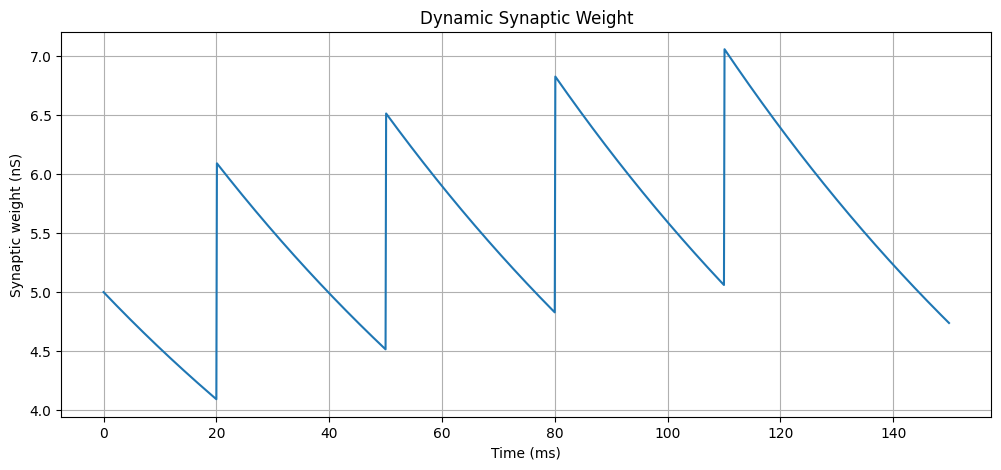

In [167]:
plt.figure(figsize=(12, 5))

plt.plot(
    SM.t/ms,
    SM.w[0]/nS
)

plt.xlabel("Time (ms)")
plt.ylabel("Synaptic weight (nS)")
plt.title("Dynamic Synaptic Weight")

plt.grid()
plt.show()

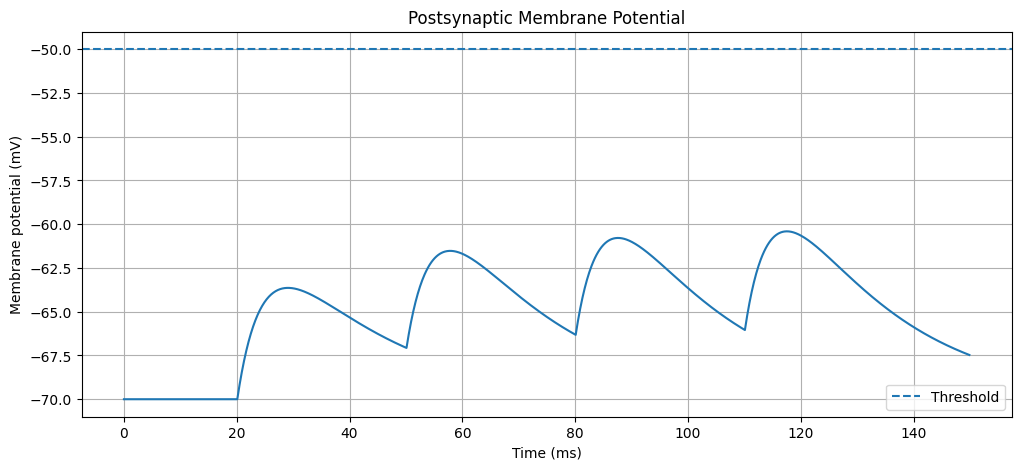

In [168]:
plt.figure(figsize=(12, 5))

plt.plot(
    M.t/ms,
    M.v[0]/mV
)

plt.axhline(
    Vth/mV,
    linestyle='--',
    label='Threshold'
)

plt.xlabel("Time (ms)")
plt.ylabel("Membrane potential (mV)")
plt.title("Postsynaptic Membrane Potential")

plt.legend()
plt.grid()
plt.show()

In [169]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

In [170]:
pre = SpikeGeneratorGroup(
    1,
    indices=[0, 0, 0],
    times=[20, 60, 100] * ms
)

In [171]:
tau_m = 20*ms
EL = -70*mV
Vth = -50*mV
Vreset = -70*mV

In [172]:
eqs = '''
dv/dt = (EL-v)/tau_m : volt
'''

In [173]:
post = NeuronGroup(
    1,
    eqs,
    threshold='v > Vth',
    reset='v = Vreset',
    method='exact'
)

post.v = EL

In [174]:
tau_pre = 20*ms
tau_post = 20*ms

dApre = 0.01
dApost = -0.012

In [175]:
wmax = 1.0

In [176]:
w_initial = 0.5

In [177]:
syn = Synapses(
    pre,
    post,
    '''
    w : 1
    dApre/dt = -Apre/tau_pre : 1 (event-driven)
    dApost/dt = -Apost/tau_post : 1 (event-driven)
    ''',

    on_pre='''
    Apre += dApre
    w = clip(w + Apost, 0, wmax)
    ''',

    on_post='''
    Apost += dApost
    w = clip(w + Apre, 0, wmax)
    '''
)

In [178]:
syn.connect()
syn.w = w_initial

In [179]:
post = SpikeGeneratorGroup(
    1,
    indices=[0, 0, 0],
    times=[25, 65, 105] * ms
)

In [180]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

# =====================================================
# PRE-SYNAPTIC SPIKES
# =====================================================

pre = SpikeGeneratorGroup(
    1,
    indices=[0, 0, 0],
    times=[20, 60, 100] * ms
)


# =====================================================
# POST-SYNAPTIC SPIKES
# =====================================================

post = SpikeGeneratorGroup(
    1,
    indices=[0, 0, 0],
    times=[25, 65, 105] * ms
)


# =====================================================
# STDP PARAMETERS
# =====================================================

tau_pre = 20*ms
tau_post = 20*ms

dApre = 0.01
dApost = -0.012

wmax = 1.0


# =====================================================
# STDP SYNAPSE
# =====================================================

syn = Synapses(
    pre,
    post,

    '''
    w : 1

    dApre/dt = -Apre/tau_pre : 1 (event-driven)

    dApost/dt = -Apost/tau_post : 1 (event-driven)
    ''',

    on_pre='''
    Apre += dApre
    w = clip(w + Apost, 0, wmax)
    ''',

    on_post='''
    Apost += dApost
    w = clip(w + Apre, 0, wmax)
    '''
)

syn.connect()

syn.w = 0.5


# =====================================================
# MONITOR
# =====================================================

M = StateMonitor(
    syn,
    ['w', 'Apre', 'Apost'],
    record=True
)


# =====================================================
# RUN
# =====================================================

run(120*ms)

WARNING    The object 'neurongroup_5' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/340574851.py', line 1, in <cell line: 0>
    post = NeuronGroup( [brian2.core.base.unused_brian_object]
WARNING    The object 'synapses_2' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/574244984.py', line 1, in <cell line: 0>
    syn = Synapses( [brian2.core.base.unused_brian_object]
WARNING    't' is an internal variable of group 'synapses_5', but also exists in the run namespace with the value array([  0.,   1.,   2., ..., 497., 498., 499.]) * msec

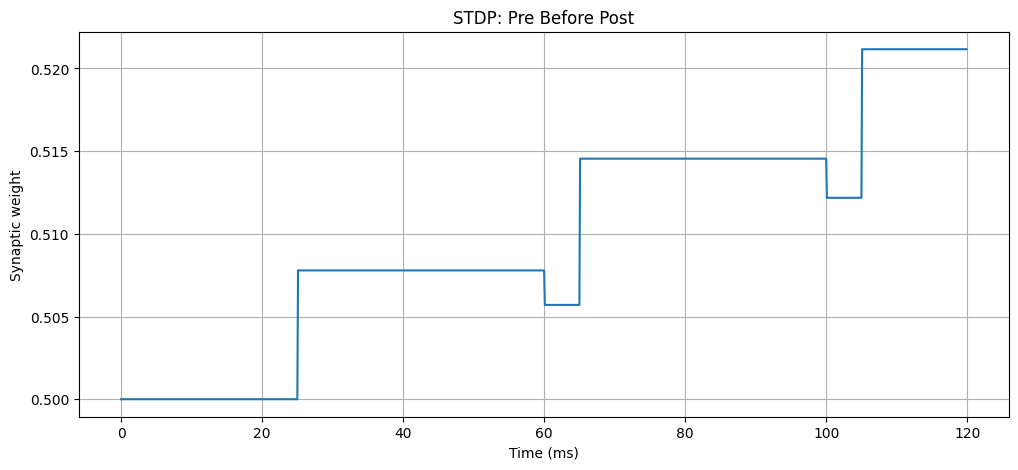

In [181]:
plt.figure(figsize=(12, 5))

plt.plot(
    M.t/ms,
    M.w[0]
)

plt.xlabel("Time (ms)")
plt.ylabel("Synaptic weight")
plt.title("STDP: Pre Before Post")

plt.grid()
plt.show()

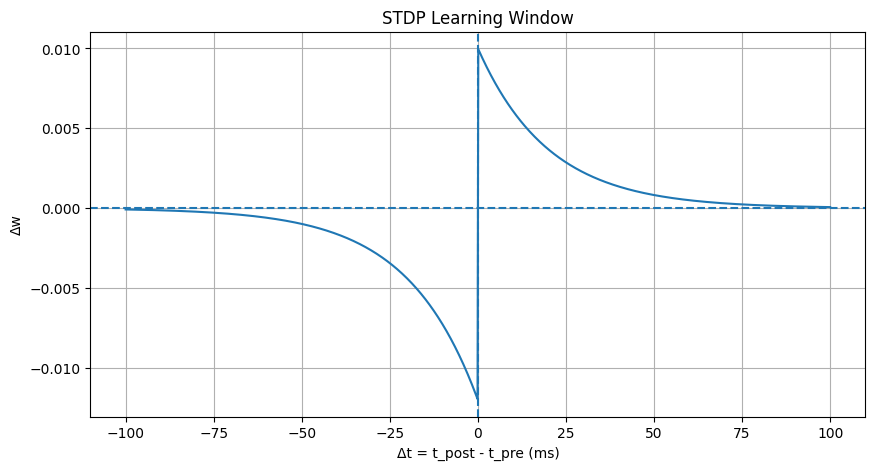

In [182]:
import numpy as np
import matplotlib.pyplot as plt

dt = np.linspace(-100, 100, 1000)

A_plus = 0.01
A_minus = 0.012

tau_plus = 20
tau_minus = 20

dw = np.where(
    dt > 0,
    A_plus * np.exp(-dt/tau_plus),
    -A_minus * np.exp(dt/tau_minus)
)

plt.figure(figsize=(10, 5))

plt.plot(dt, dw)

plt.axhline(0, linestyle='--')

plt.axvline(0, linestyle='--')

plt.xlabel("Δt = t_post - t_pre (ms)")
plt.ylabel("Δw")

plt.title("STDP Learning Window")

plt.grid()
plt.show()

In [183]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

In [184]:
pre = SpikeGeneratorGroup(
    1,
    indices=[
        0, 0, 0, 0, 0,
        0, 0, 0, 0, 0
    ],
    times=[
        20, 40, 60, 80, 100,
        120, 140, 160, 180, 200
    ] * ms
)

In [185]:
C = 200*pF
gL = 10*nS

EL = -70*mV
Vth = -50*mV
Vreset = -70*mV

E_syn = 0*mV
tau_syn = 5*ms

In [186]:
eqs = '''
dv/dt = (gL*(EL-v) + I_syn) / C : volt

I_syn = g_syn*(E_syn-v) : amp

dg_syn/dt = -g_syn/tau_syn : siemens
'''

In [187]:
post = NeuronGroup(
    1,
    eqs,
    threshold='v > Vth',
    reset='v = Vreset',
    method='euler'
)

post.v = EL
post.g_syn = 0*nS

In [188]:
U = 0.2

tau_fac = 100*ms
tau_rec = 800*ms

In [189]:
syn = Synapses(
    pre,
    post,
    '''
    du/dt = (U-u)/tau_fac : 1 (event-driven)

    dx/dt = (1-x)/tau_rec : 1 (event-driven)

    w : siemens
    ''',

    on_pre='''
    u += U*(1-u)
    x *= (1-u)

    g_syn_post += w*u*x
    '''
)

syn.connect()

syn.u = U
syn.x = 1
syn.w = 10*nS

In [190]:
M = StateMonitor(
    post,
    ['v', 'g_syn'],
    record=True
)

SM = StateMonitor(
    syn,
    ['u', 'x'],
    record=True
)

S = SpikeMonitor(pre)

In [191]:
run(250*ms)

WARNING    't' is an internal variable of group 'synapses_2', but also exists in the run namespace with the value array([  0.,   1.,   2., ..., 497., 498., 499.]) * msecond. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'x' is an internal variable of group 'synapses_2', but also exists in the run namespace with the value array([0.02374118, 0.85662622, 0.6629947 , ..., 0.97776997, 0.64957689,
       0.61122723]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


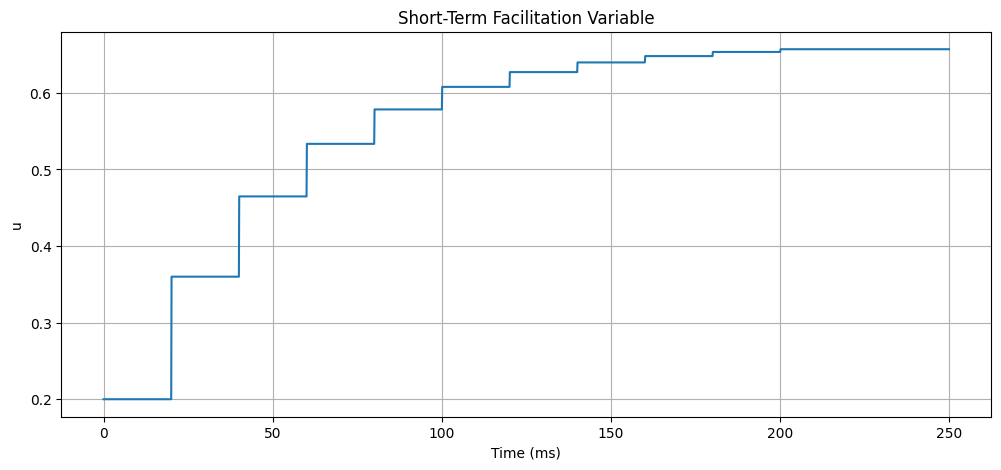

In [192]:
plt.figure(figsize=(12, 5))

plt.plot(
    SM.t/ms,
    SM.u[0]
)

plt.xlabel("Time (ms)")
plt.ylabel("u")
plt.title("Short-Term Facilitation Variable")

plt.grid()
plt.show()

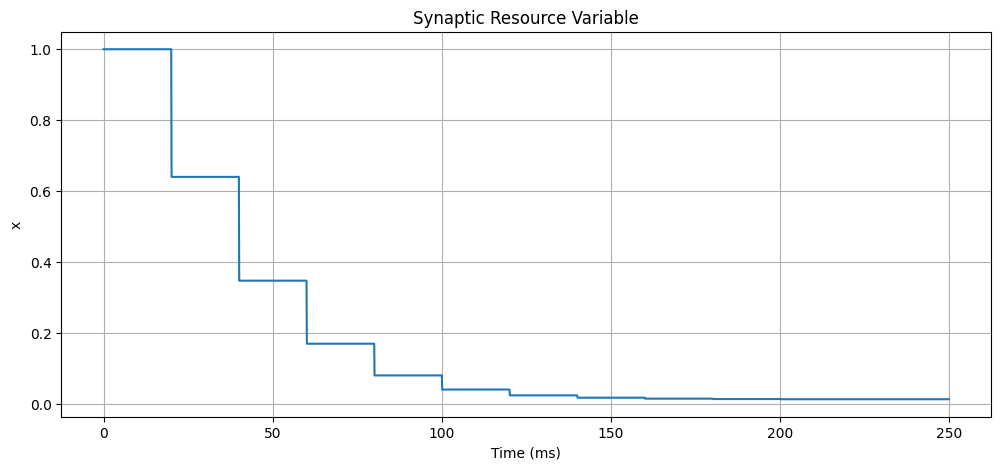

In [193]:
plt.figure(figsize=(12, 5))

plt.plot(
    SM.t/ms,
    SM.x[0]
)

plt.xlabel("Time (ms)")
plt.ylabel("x")
plt.title("Synaptic Resource Variable")

plt.grid()
plt.show()

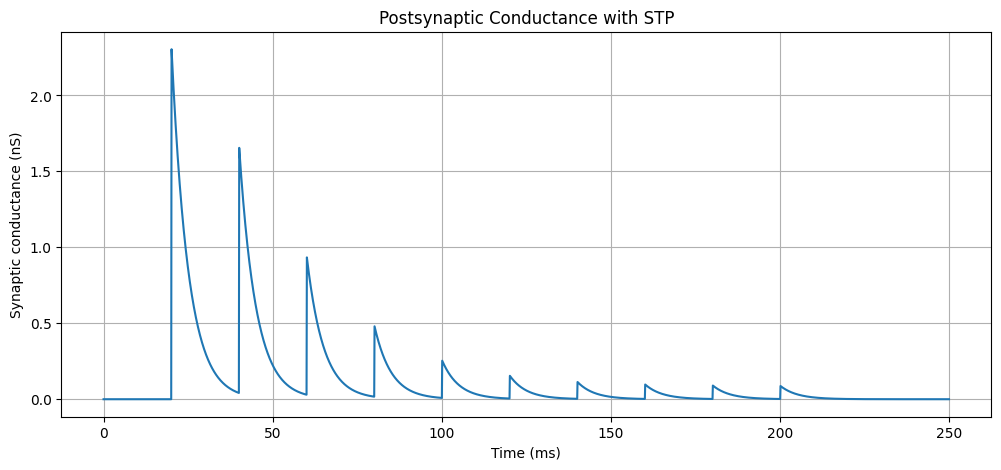

In [194]:
plt.figure(figsize=(12, 5))

plt.plot(
    M.t/ms,
    M.g_syn[0]/nS
)

plt.xlabel("Time (ms)")
plt.ylabel("Synaptic conductance (nS)")
plt.title("Postsynaptic Conductance with STP")

plt.grid()
plt.show()

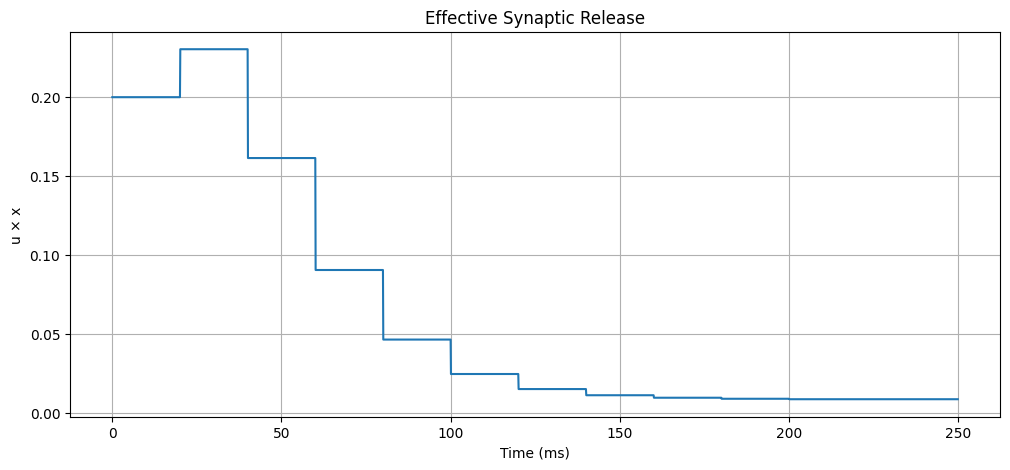

In [195]:
release = SM.u[0] * SM.x[0]

plt.figure(figsize=(12, 5))

plt.plot(
    SM.t/ms,
    release
)

plt.xlabel("Time (ms)")
plt.ylabel("u × x")
plt.title("Effective Synaptic Release")

plt.grid()
plt.show()

In [196]:
from brian2 import *
import matplotlib.pyplot as plt
import numpy as np

start_scope()

In [197]:
N = 10

tau_m = 20*ms
EL = -70*mV
Vth = -50*mV
Vreset = -70*mV

C = 200*pF
gL = 10*nS

E_exc = 0*mV
tau_exc = 5*ms

In [198]:
eqs = '''
dv/dt = (gL*(EL-v) + I_exc) / C : volt

I_exc = g_exc*(E_exc-v) : amp

dg_exc/dt = -g_exc/tau_exc : siemens
'''

In [199]:
G = NeuronGroup(
    N,
    eqs,
    threshold='v > Vth',
    reset='v = Vreset',
    method='euler'
)

G.v = EL
G.g_exc = 0*nS

In [200]:
S = Synapses(
    G,
    G,
    on_pre='''
    g_exc_post += 3*nS
    '''
)

In [201]:
S.connect(
    p=0.3,
    condition='i != j'
)

WARNING    'i' is an internal variable of group 'synapses_4', but also exists in the run namespace with the value 2. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'j' is an internal variable of group 'synapses_4', but also exists in the run namespace with the value np.int32(14). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


In [202]:
stim = SpikeGeneratorGroup(
    1,
    indices=[0, 0, 0],
    times=[10, 60, 110]*ms
)

In [203]:
input_syn = Synapses(
    stim,
    G,
    on_pre='''
    g_exc_post += 15*nS
    '''
)

input_syn.connect(
    i=0,
    j=0
)

In [204]:
M = StateMonitor(
    G,
    'v',
    record=True
)

spikes = SpikeMonitor(G)

In [205]:
run(150*ms)

In [206]:
print("Number of spikes:", spikes.num_spikes)
print("Spiking neurons:", np.unique(spikes.i))

Number of spikes: 0
Spiking neurons: []


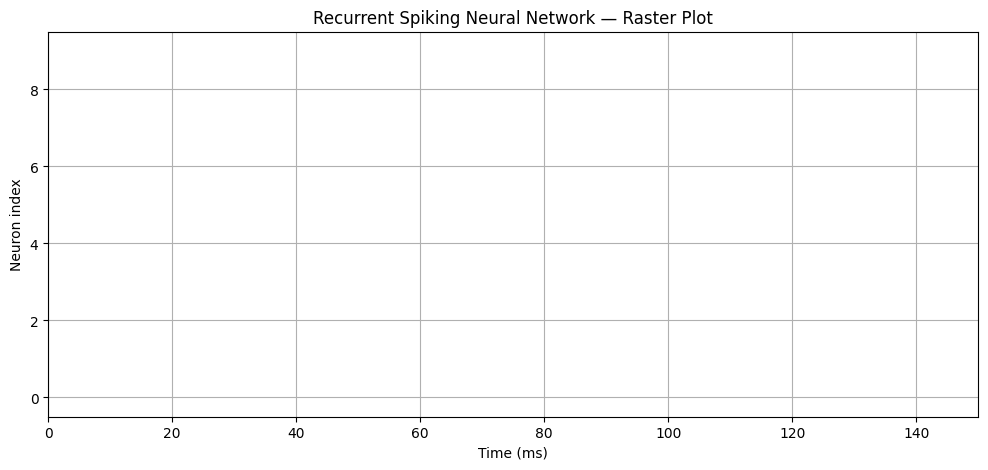

In [207]:
plt.figure(figsize=(12, 5))

plt.plot(
    spikes.t/ms,
    spikes.i,
    '.'
)

plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Recurrent Spiking Neural Network — Raster Plot')

plt.xlim(0, 150)
plt.ylim(-0.5, N-0.5)

plt.grid()

plt.show()

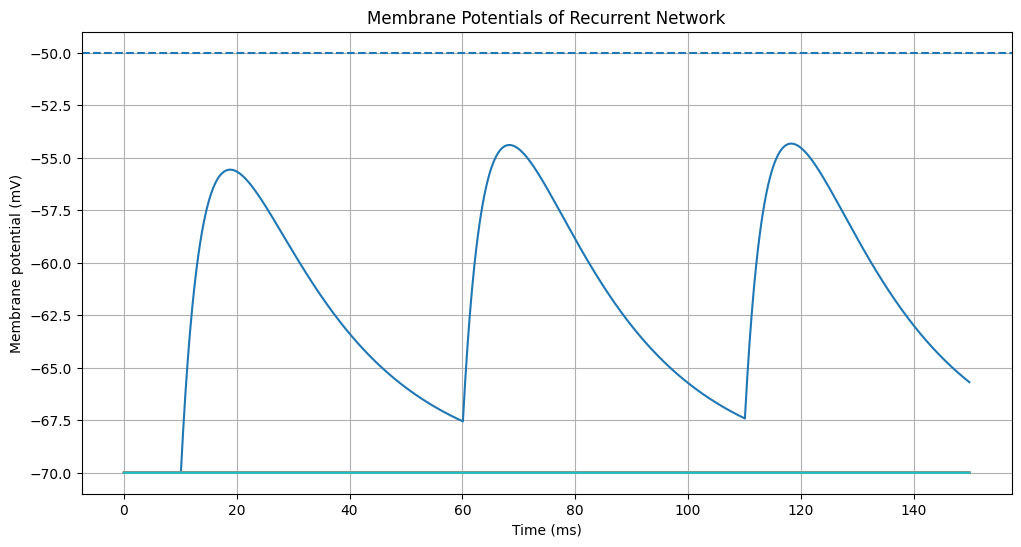

In [208]:
plt.figure(figsize=(12, 6))

for i in range(N):
    plt.plot(
        M.t/ms,
        M.v[i]/mV,
        label=f'Neuron {i}'
    )

plt.axhline(
    Vth/mV,
    linestyle='--',
    label='Threshold'
)

plt.xlabel('Time (ms)')
plt.ylabel('Membrane potential (mV)')
plt.title('Membrane Potentials of Recurrent Network')

plt.grid()
plt.show()

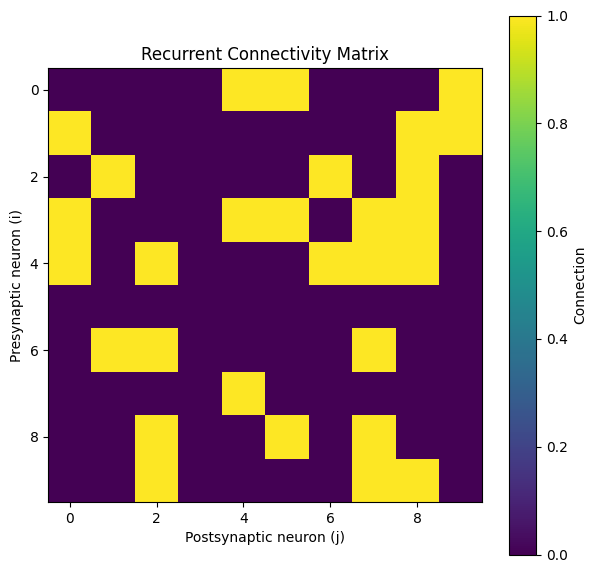

In [209]:
plt.figure(figsize=(7, 7))

connectivity = np.zeros((N, N))

for i, j in zip(S.i[:], S.j[:]):
    connectivity[int(i), int(j)] = 1

plt.imshow(connectivity)

plt.xlabel('Postsynaptic neuron (j)')
plt.ylabel('Presynaptic neuron (i)')
plt.title('Recurrent Connectivity Matrix')

plt.colorbar(label='Connection')

plt.show()

In [210]:
from brian2 import *
import matplotlib.pyplot as plt
import numpy as np

start_scope()

N = 5

G = NeuronGroup(
    N,
    'dv/dt = 0*Hz : 1'
)

S = Synapses(
    G,
    G
)

S.connect(
    i=[0, 0, 1, 2, 3],
    j=[1, 2, 2, 3, 4]
)

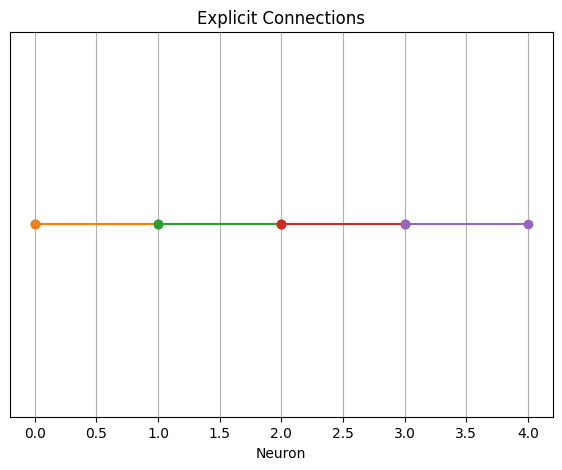

In [211]:
plt.figure(figsize=(7, 5))

for i, j in zip(S.i[:], S.j[:]):
    plt.plot([i, j], [0, 0], 'o-')

plt.xlabel("Neuron")
plt.yticks([])
plt.title("Explicit Connections")

plt.grid()
plt.show()

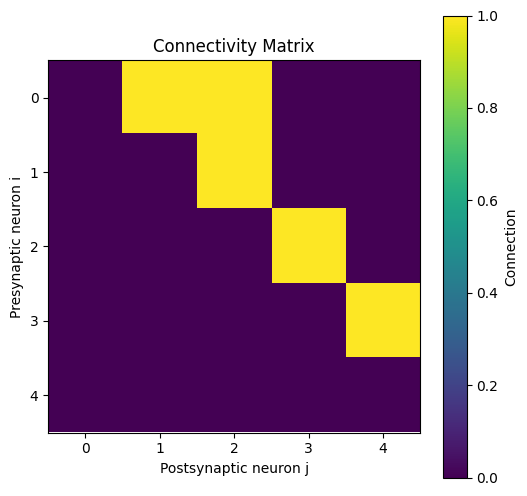

In [212]:
matrix = np.zeros((N, N))

for i, j in zip(S.i[:], S.j[:]):
    matrix[int(i), int(j)] = 1

plt.figure(figsize=(6, 6))
plt.imshow(matrix)

plt.xlabel("Postsynaptic neuron j")
plt.ylabel("Presynaptic neuron i")
plt.title("Connectivity Matrix")

plt.colorbar(label="Connection")
plt.show()

In [213]:
start_scope()

N = 5

G1 = NeuronGroup(
    N,
    'dv/dt = 0*Hz : 1'
)

G2 = NeuronGroup(
    N,
    'dv/dt = 0*Hz : 1'
)

S = Synapses(
    G1,
    G2
)

S.connect(
    j='i'
)

print("Number of synapses:", len(S.i[:]))

WARNING    The object 'synapses_6' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/2960974709.py', line 14, in <cell line: 0>
    S = Synapses( [brian2.core.base.unused_brian_object]
WARNING    'i' is an internal variable of group 'synapses_4', but also exists in the run namespace with the value np.int32(3). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Number of synapses: 5


In [214]:
start_scope()

N = 5

G1 = NeuronGroup(
    N,
    'dv/dt = 0*Hz : 1'
)

G2 = NeuronGroup(
    N,
    'dv/dt = 0*Hz : 1'
)

S = Synapses(
    G1,
    G2
)

S.connect()

print("Number of synapses:", len(S.i[:]))

WARNING    The object 'synapses_4' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/2803793419.py', line 15, in <cell line: 0>
    S = Synapses( [brian2.core.base.unused_brian_object]
WARNING    The object 'neurongroup_8' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/2803793419.py', line 5, in <cell line: 0>
    G1 = NeuronGroup( [brian2.core.base.unused_brian_object]
WARNING    The object 'neurongroup_9' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variab

Number of synapses: 25


In [215]:
start_scope()

N = 5

G = NeuronGroup(
    N,
    'dv/dt = 0*Hz : 1'
)

S = Synapses(
    G,
    G
)

S.connect(
    condition='i != j'
)

print("Number of synapses:", len(S.i[:]))

WARNING    The object 'neurongroup_3' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/2960974709.py', line 9, in <cell line: 0>
    G = NeuronGroup( [brian2.core.base.unused_brian_object]
WARNING    The object 'synapses_6' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/520976737.py', line 15, in <cell line: 0>
    S = Synapses( [brian2.core.base.unused_brian_object]
WARNING    'j' is an internal variable of group 'synapses_4', but also exists in the run namespace with the value np.int32(4). The internal variable will be used. [brian2.g

Number of synapses: 20


In [216]:
start_scope()

N = 100

G = NeuronGroup(
    N,
    'dv/dt = 0*Hz : 1'
)

S = Synapses(
    G,
    G
)

S.connect(
    p=0.2,
    condition='i != j'
)

print("Number of synapses:", len(S.i[:]))

WARNING    The object 'synapses_4' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/3970635465.py', line 10, in <cell line: 0>
    S = Synapses( [brian2.core.base.unused_brian_object]
WARNING    The object 'neurongroup_8' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/3970635465.py', line 5, in <cell line: 0>
    G = NeuronGroup( [brian2.core.base.unused_brian_object]
WARNING    'i' is an internal variable of group 'synapses_6', but also exists in the run namespace with the value np.int32(3). The internal variable will be used. [brian2.

Number of synapses: 2035


WARNING    The object 'synapses_6' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/3950236502.py', line 10, in <cell line: 0>
    S = Synapses( [brian2.core.base.unused_brian_object]
WARNING    The object 'neurongroup_3' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/3950236502.py', line 5, in <cell line: 0>
    G = NeuronGroup( [brian2.core.base.unused_brian_object]


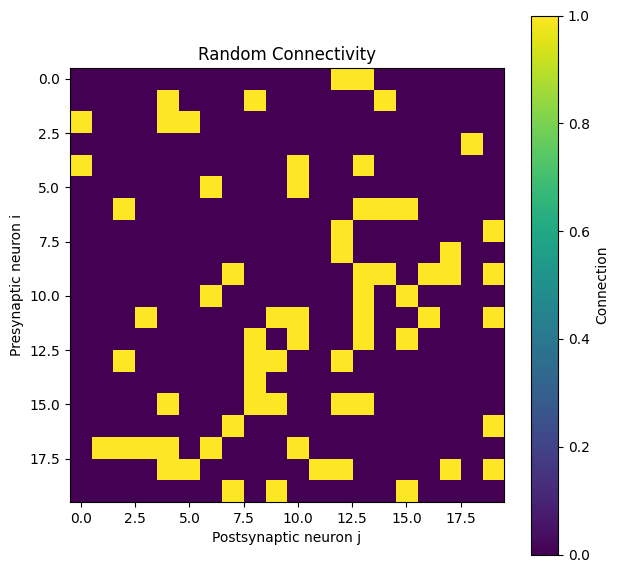

In [217]:
start_scope()

N = 20

G = NeuronGroup(
    N,
    'dv/dt = 0*Hz : 1'
)

S = Synapses(
    G,
    G
)

S.connect(
    p=0.2,
    condition='i != j'
)

matrix = np.zeros((N, N))

for i, j in zip(S.i[:], S.j[:]):
    matrix[int(i), int(j)] = 1

plt.figure(figsize=(7, 7))

plt.imshow(matrix)

plt.xlabel("Postsynaptic neuron j")
plt.ylabel("Presynaptic neuron i")
plt.title("Random Connectivity")

plt.colorbar(label="Connection")

plt.show()

In [218]:
start_scope()

N = 6

G = NeuronGroup(
    N,
    'dv/dt = 0*Hz : 1'
)

S = Synapses(
    G,
    G
)

S.connect(
    condition='j == i + 1'
)

print("Connections:")
for i, j in zip(S.i[:], S.j[:]):
    print(f"{i} -> {j}")

WARNING    The object 'synapses_4' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/3323926283.py', line 10, in <cell line: 0>
    S = Synapses( [brian2.core.base.unused_brian_object]
WARNING    The object 'neurongroup_8' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/3323926283.py', line 5, in <cell line: 0>
    G = NeuronGroup( [brian2.core.base.unused_brian_object]
WARNING    'i' is an internal variable of group 'synapses_6', but also exists in the run namespace with the value np.int32(19). The internal variable will be used. [brian2

Connections:
0 -> 1
1 -> 2
2 -> 3
3 -> 4
4 -> 5


In [219]:
start_scope()

N = 10

G = NeuronGroup(
    N,
    'dv/dt = 0*Hz : 1'
)

S = Synapses(
    G,
    G
)

S.connect(
    condition='j == (i + 1) % N_pre'
)

print("Connections:")

for i, j in zip(S.i[:], S.j[:]):
    print(f"{i} -> {j}")

WARNING    The object 'synapses_6' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/2049722594.py', line 10, in <cell line: 0>
    S = Synapses( [brian2.core.base.unused_brian_object]
WARNING    The object 'neurongroup_3' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/2049722594.py', line 5, in <cell line: 0>
    G = NeuronGroup( [brian2.core.base.unused_brian_object]
WARNING    'i' is an internal variable of group 'synapses_4', but also exists in the run namespace with the value np.int32(4). The internal variable will be used. [brian2.

Connections:
0 -> 1
1 -> 2
2 -> 3
3 -> 4
4 -> 5
5 -> 6
6 -> 7
7 -> 8
8 -> 9
9 -> 0


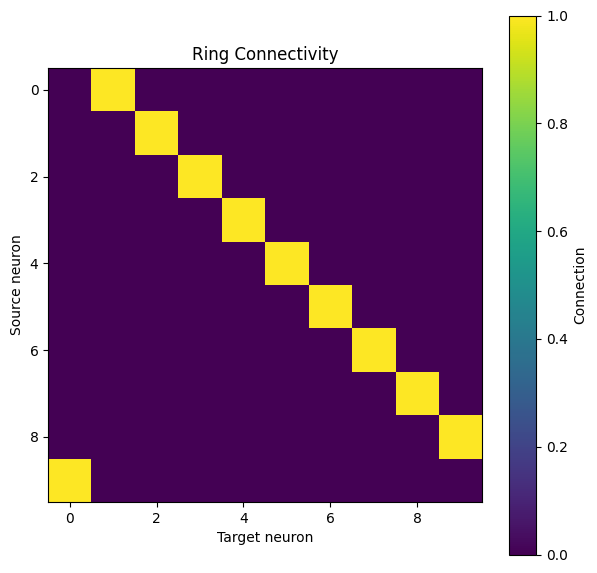

In [220]:
matrix = np.zeros((N, N))

for i, j in zip(S.i[:], S.j[:]):
    matrix[int(i), int(j)] = 1

plt.figure(figsize=(7, 7))

plt.imshow(matrix)

plt.xlabel("Target neuron")
plt.ylabel("Source neuron")
plt.title("Ring Connectivity")

plt.colorbar(label="Connection")

plt.show()

In [221]:
start_scope()

N = 20

G = NeuronGroup(
    N,
    'dv/dt = 0*Hz : 1'
)

S = Synapses(
    G,
    G
)

S.connect(condition=j == '(i-1) % N or j == (i+1) % N')


print("Number of connections:", len(S.i[:]))

WARNING    The object 'synapses_4' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/1089518383.py', line 10, in <cell line: 0>
    S = Synapses( [brian2.core.base.unused_brian_object]
WARNING    The object 'neurongroup_8' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/1089518383.py', line 5, in <cell line: 0>
    G = NeuronGroup( [brian2.core.base.unused_brian_object]


Number of connections: 0


In [222]:
out_degree = np.bincount(
    np.array(S.i[:], dtype=int),
    minlength=N
)

print("Out-degree:")
print(out_degree)

Out-degree:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [223]:
in_degree = np.bincount(
    np.array(S.j[:], dtype=int),
    minlength=N
)

print("In-degree:")
print(in_degree)

In-degree:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [224]:
start_scope()

In [225]:
from brian2 import *
import matplotlib.pyplot as plt
import numpy as np

start_scope()

In [226]:
N = 3

C = 200*pF
gL = 10*nS

EL = -70*mV
Vth = -50*mV
Vreset = -70*mV

E_exc = 0*mV
tau_exc = 5*ms

eqs = '''
dv/dt = (gL*(EL-v) + I_exc) / C : volt

I_exc = g_exc*(E_exc-v) : amp

dg_exc/dt = -g_exc/tau_exc : siemens
'''

In [227]:
G = NeuronGroup(
    N,
    eqs,
    threshold='v > Vth',
    reset='v = Vreset',
    method='euler'
)

G.v = EL
G.g_exc = 0*nS

In [228]:
input_group = SpikeGeneratorGroup(
    N,
    indices=[0, 1, 2],
    times=[10, 10, 10]*ms
)

In [229]:
S = Synapses(
    input_group,
    G,
    '''
    w : siemens
    ''',
    on_pre='''
    g_exc_post += w
    '''
)

WARNING    The object 'synapses_6' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/4247742853.py', line 10, in <cell line: 0>
    S = Synapses( [brian2.core.base.unused_brian_object]
WARNING    The object 'neurongroup_3' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/4247742853.py', line 5, in <cell line: 0>
    G = NeuronGroup( [brian2.core.base.unused_brian_object]


In [230]:
S.connect(
    j='i'
)

WARNING    'i' is an internal variable of group 'synapses_4', but also exists in the run namespace with the value np.int32(9). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


In [231]:
S.w = [5, 10, 20]*nS

In [232]:
M = StateMonitor(
    G,
    ['v', 'g_exc'],
    record=True
)

spikes = SpikeMonitor(G)

In [233]:
run(50*ms)

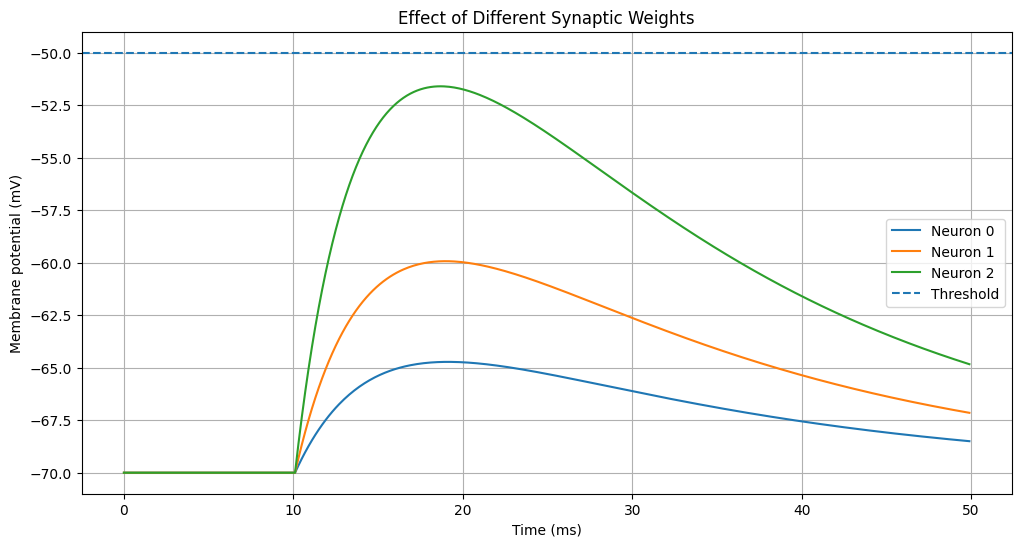

In [234]:
plt.figure(figsize=(12, 6))

for i in range(N):
    plt.plot(
        M.t/ms,
        M.v[i]/mV,
        label=f'Neuron {i}'
    )

plt.axhline(
    Vth/mV,
    linestyle='--',
    label='Threshold'
)

plt.xlabel('Time (ms)')
plt.ylabel('Membrane potential (mV)')
plt.title('Effect of Different Synaptic Weights')

plt.legend()
plt.grid()

plt.show()

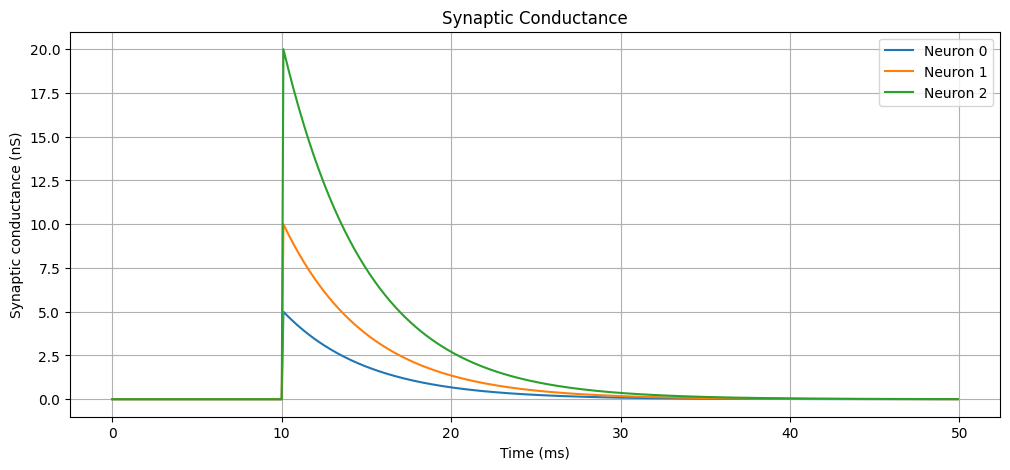

In [235]:
plt.figure(figsize=(12, 5))

for i in range(N):
    plt.plot(
        M.t/ms,
        M.g_exc[i]/nS,
        label=f'Neuron {i}'
    )

plt.xlabel('Time (ms)')
plt.ylabel('Synaptic conductance (nS)')
plt.title('Synaptic Conductance')

plt.legend()
plt.grid()

plt.show()

In [238]:
start_scope()

input_group = SpikeGeneratorGroup(
    3,
    indices=[0, 1, 2],
    times=[10, 12, 14]*ms
)

G = NeuronGroup(
    1,
    eqs,
    threshold='v > Vth',
    reset='v = Vreset',
    method='euler'
)

G.v = EL
G.g_exc = 0*nS

S = Synapses(
    input_group,
    G,
    '''
    w : siemens
    ''',
    on_pre='''
    g_exc_post += w
    '''
)

S.connect(
    i=[0, 1, 2],
    j=[0, 0, 0]
)


S.w = 10*nS

In [239]:
M = StateMonitor(
    G,
    ['v', 'g_exc'],
    record=True
)

spikes = SpikeMonitor(G)

run(50*ms)

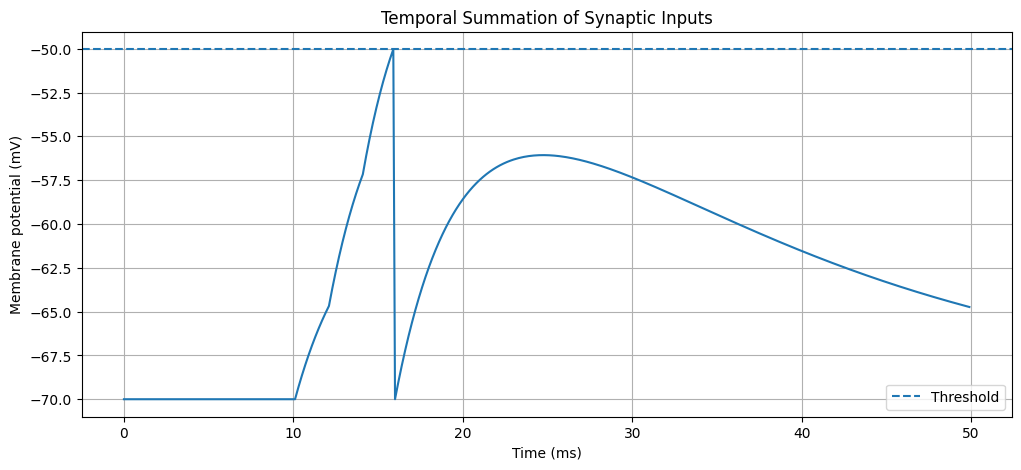

In [240]:
plt.figure(figsize=(12, 5))

plt.plot(
    M.t/ms,
    M.v[0]/mV
)

plt.axhline(
    Vth/mV,
    linestyle='--',
    label='Threshold'
)

plt.xlabel('Time (ms)')
plt.ylabel('Membrane potential (mV)')
plt.title('Temporal Summation of Synaptic Inputs')

plt.legend()
plt.grid()

plt.show()

In [241]:
start_scope()

G = NeuronGroup(
    1,
    eqs,
    threshold='v > Vth',
    reset='v = Vreset',
    method='euler'
)

G.v = EL
G.g_exc = 0*nS

In [242]:
stim = SpikeGeneratorGroup(
    1,
    indices=[0],
    times=[10]*ms
)

In [243]:
S = Synapses(
    stim,
    G,
    '''
    w : siemens
    ''',
    on_pre='''
    g_exc_post += w
    '''
)

S.connect(
    i=0,
    j=0
)

S.w = 20*nS
S.delay = 5*ms

In [244]:
M = StateMonitor(
    G,
    ['v', 'g_exc'],
    record=True
)

spikes = SpikeMonitor(G)

run(50*ms)

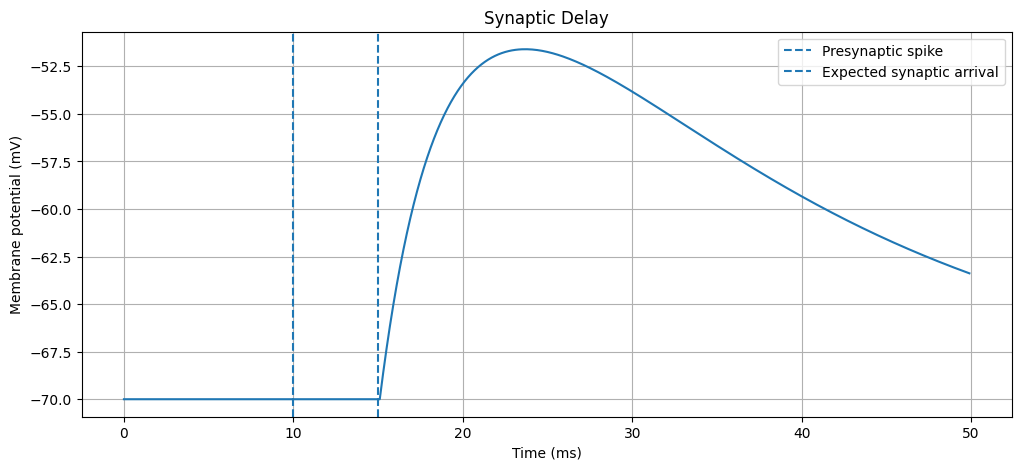

In [245]:
plt.figure(figsize=(12, 5))

plt.plot(
    M.t/ms,
    M.v[0]/mV
)

plt.axvline(
    10,
    linestyle='--',
    label='Presynaptic spike'
)

plt.axvline(
    15,
    linestyle='--',
    label='Expected synaptic arrival'
)

plt.xlabel('Time (ms)')
plt.ylabel('Membrane potential (mV)')
plt.title('Synaptic Delay')

plt.legend()
plt.grid()

plt.show()

In [246]:
start_scope()

stim = SpikeGeneratorGroup(
    3,
    indices=[0, 1, 2],
    times=[10, 10, 10]*ms
)

G = NeuronGroup(
    1,
    eqs,
    threshold='v > Vth',
    reset='v = Vreset',
    method='euler'
)

G.v = EL
G.g_exc = 0*nS

S = Synapses(
    stim,
    G,
    '''
    w : siemens
    ''',
    on_pre='''
    g_exc_post += w
    '''
)

S.connect(
    i=[0, 1, 2],
    j=[0, 0, 0]
)

S.w = [8, 8, 8]*nS
S.delay = [2, 5, 10]*ms

In [247]:
start_scope()

N = 20

G = NeuronGroup(
    N,
    eqs,
    threshold='v > Vth',
    reset='v = Vreset',
    method='euler'
)

G.v = EL
G.g_exc = 0*nS

S = Synapses(
    G,
    G,
    '''
    w : siemens
    ''',
    on_pre='''
    g_exc_post += w
    '''
)

S.connect(
    condition='i != j',
    p=0.2
)

S.w = '2*nS + 8*nS*rand()'

print("Number of synapses:", len(S.i[:]))

WARNING    'i' is an internal variable of group 'synapses_7', but also exists in the run namespace with the value 2. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'j' is an internal variable of group 'synapses_7', but also exists in the run namespace with the value np.int32(0). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    The object 'synapses_4' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/221395682.py', line 20, in <cell line: 0>
    S = Synapses( [brian2.core.base.unused_brian_object]
WARNING    The object 'neurongroup_9' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in

Number of synapses: 75


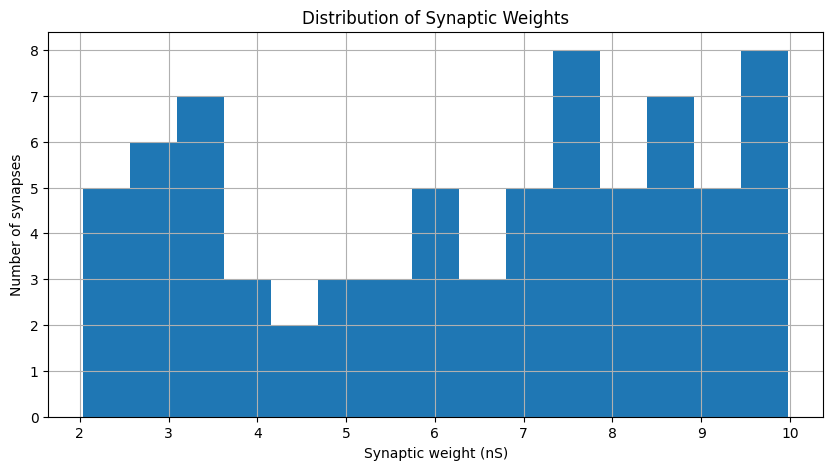

In [248]:
weights = np.array(S.w[:] / nS)

plt.figure(figsize=(10, 5))

plt.hist(weights, bins=15)

plt.xlabel('Synaptic weight (nS)')
plt.ylabel('Number of synapses')
plt.title('Distribution of Synaptic Weights')

plt.grid()

plt.show()

In [249]:
weights = np.arange(2, 22, 2)

spike_counts = []

for weight in weights:

    start_scope()

    G = NeuronGroup(
        1,
        eqs,
        threshold='v > Vth',
        reset='v = Vreset',
        method='euler'
    )

    G.v = EL
    G.g_exc = 0*nS

    stim = SpikeGeneratorGroup(
        1,
        indices=[0],
        times=[10]*ms
    )

    S = Synapses(
        stim,
        G,
        '''
        w : siemens
        ''',
        on_pre='''
        g_exc_post += w
        '''
    )

    S.connect(
        i=0,
        j=0
    )

    S.w = weight*nS

    M_spike = SpikeMonitor(G)

    run(50*ms)

    spike_counts.append(M_spike.num_spikes)

WARNING    The object 'synapses_7' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/3126055852.py', line 16, in <cell line: 0>
    S = Synapses( [brian2.core.base.unused_brian_object]
WARNING    The object 'neurongroup_13' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File '/tmp/ipykernel_2493/3126055852.py', line 5, in <cell line: 0>
    G = NeuronGroup( [brian2.core.base.unused_brian_object]


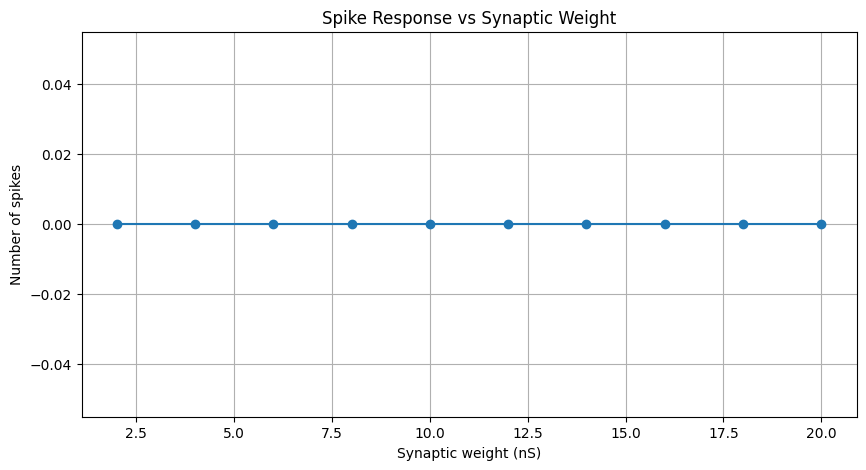

In [250]:
plt.figure(figsize=(10, 5))

plt.plot(
    weights,
    spike_counts,
    'o-'
)

plt.xlabel('Synaptic weight (nS)')
plt.ylabel('Number of spikes')

plt.title('Spike Response vs Synaptic Weight')

plt.grid()

plt.show()

In [270]:
from brian2 import *
import matplotlib.pyplot as plt
import numpy as np

start_scope()

# ============================================================
# PARAMETERS
# ============================================================

N_E = 80
N_I = 20

C = 200*pF
gL = 10*nS

EL = -70*mV
Vth = -50*mV
Vreset = -70*mV

E_exc = 0*mV
E_inh = -80*mV

tau_exc = 5*ms
tau_inh = 10*ms


# ============================================================
# NEURON MODEL
# ============================================================

eqs = '''
dv/dt = (
    gL*(EL-v)
    + g_exc*(E_exc-v)
    + g_inh*(E_inh-v)
) / C : volt

dg_exc/dt = -g_exc/tau_exc : siemens

dg_inh/dt = -g_inh/tau_inh : siemens
'''


# ============================================================
# EXCITATORY POPULATION
# ============================================================

E = NeuronGroup(
    N_E,
    eqs,
    threshold='v > Vth',
    reset='v = Vreset',
    method='euler'
)

E.v = EL
E.g_exc = 0*nS
E.g_inh = 0*nS


# ============================================================
# INHIBITORY POPULATION
# ============================================================

I = NeuronGroup(
    N_I,
    eqs,
    threshold='v > Vth',
    reset='v = Vreset',
    method='euler'
)

I.v = EL
I.g_exc = 0*nS
I.g_inh = 0*nS


# ============================================================
# E -> E
# ============================================================

S_EE = Synapses(
    E,
    E,
    on_pre='''
    g_exc_post += 2*nS
    '''
)

S_EE.connect(
    condition='i != j',
    p=0.15
)


# ============================================================
# E -> I
# ============================================================

S_EI = Synapses(
    E,
    I,
    on_pre='''
    g_exc_post += 3*nS
    '''
)

S_EI.connect(
    p=0.30
)


# ============================================================
# I -> E
# ============================================================

S_IE = Synapses(
    I,
    E,
    on_pre='''
    g_inh_post += 6*nS
    '''
)

S_IE.connect(
    p=0.30
)


# ============================================================
# I -> I
# ============================================================

S_II = Synapses(
    I,
    I,
    on_pre='''
    g_inh_post += 4*nS
    '''
)

S_II.connect(
    condition='i != j',
    p=0.20
)


# ============================================================
# STRONG EXTERNAL INPUT
# ============================================================

stim = PoissonGroup(
    20,
    rates=100*Hz
)

S_input = Synapses(
    stim,
    E,
    on_pre='''
    g_exc_post += 20*nS
    '''
)

# Connect each Poisson source to one excitatory neuron
S_input.connect(
    j='i'
)


# ============================================================
# MONITORS
# ============================================================

spikes_E = SpikeMonitor(E)
spikes_I = SpikeMonitor(I)

rate_E = PopulationRateMonitor(E)
rate_I = PopulationRateMonitor(I)

M_E = StateMonitor(
    E,
    'v',
    record=[0, 1, 2]
)

M_I = StateMonitor(
    I,
    'v',
    record=[0, 1, 2]
)


# ============================================================
# RUN
# ============================================================

run(1*second)

WARNING    'i' is an internal variable of group 'synapses_12', but also exists in the run namespace with the value 2. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'j' is an internal variable of group 'synapses_12', but also exists in the run namespace with the value np.int32(0). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'i' is an internal variable of group 'synapses_9', but also exists in the run namespace with the value 2. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'j' is an internal variable of group 'synapses_9', but also exists in the run namespace with the value np.int32(0). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'dt' is an internal variable of group 'poissongroup_2', but also exists in the run namespace with the value array([-100.       ,  -

In [271]:
print("Excitatory spikes:", spikes_E.num_spikes)
print("Inhibitory spikes:", spikes_I.num_spikes)

Excitatory spikes: 1382
Inhibitory spikes: 797


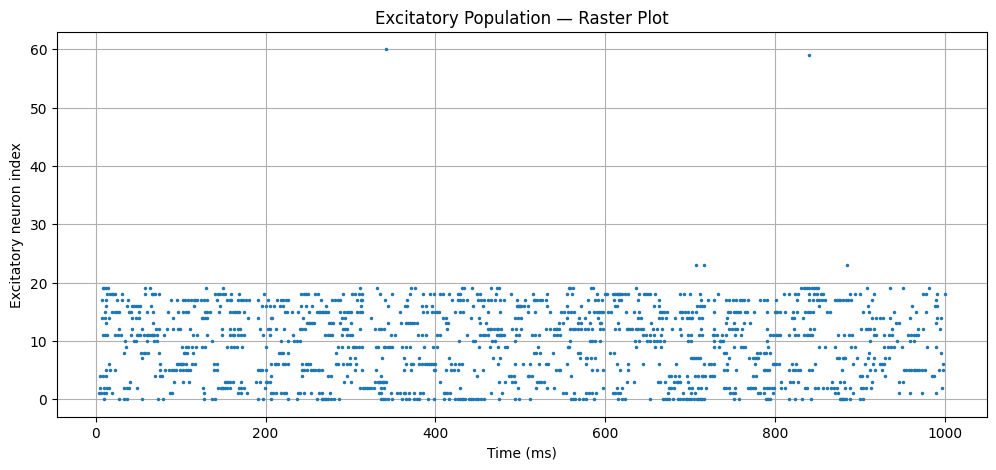

In [272]:
plt.figure(figsize=(12, 5))

if spikes_E.num_spikes > 0:
    plt.plot(
        spikes_E.t/ms,
        spikes_E.i,
        '.',
        markersize=3
    )
else:
    plt.text(
        0.5,
        0.5,
        'NO EXCITATORY SPIKES',
        transform=plt.gca().transAxes,
        ha='center',
        va='center'
    )

plt.xlabel('Time (ms)')
plt.ylabel('Excitatory neuron index')
plt.title('Excitatory Population — Raster Plot')
plt.grid()

plt.show()

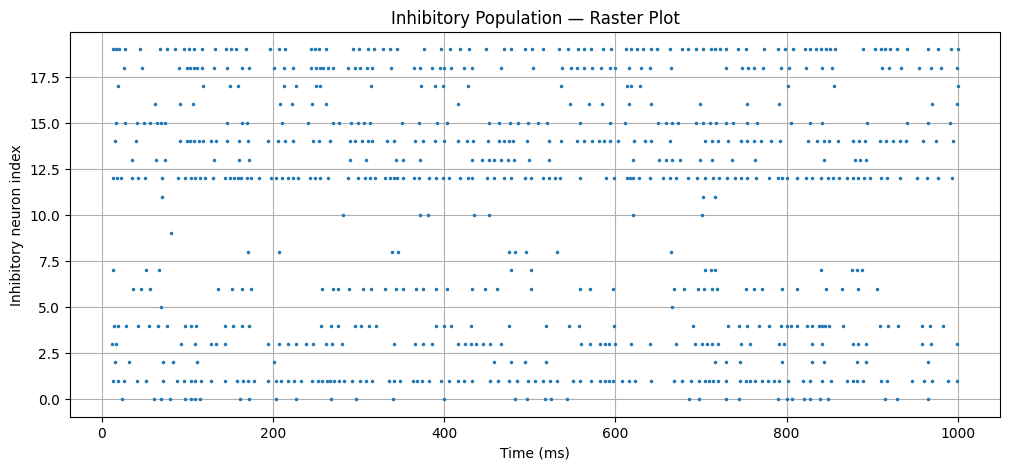

In [273]:
plt.figure(figsize=(12, 5))

if spikes_I.num_spikes > 0:
    plt.plot(
        spikes_I.t/ms,
        spikes_I.i,
        '.',
        markersize=3
    )
else:
    plt.text(
        0.5,
        0.5,
        'NO INHIBITORY SPIKES',
        transform=plt.gca().transAxes,
        ha='center',
        va='center'
    )

plt.xlabel('Time (ms)')
plt.ylabel('Inhibitory neuron index')
plt.title('Inhibitory Population — Raster Plot')
plt.grid()

plt.show()

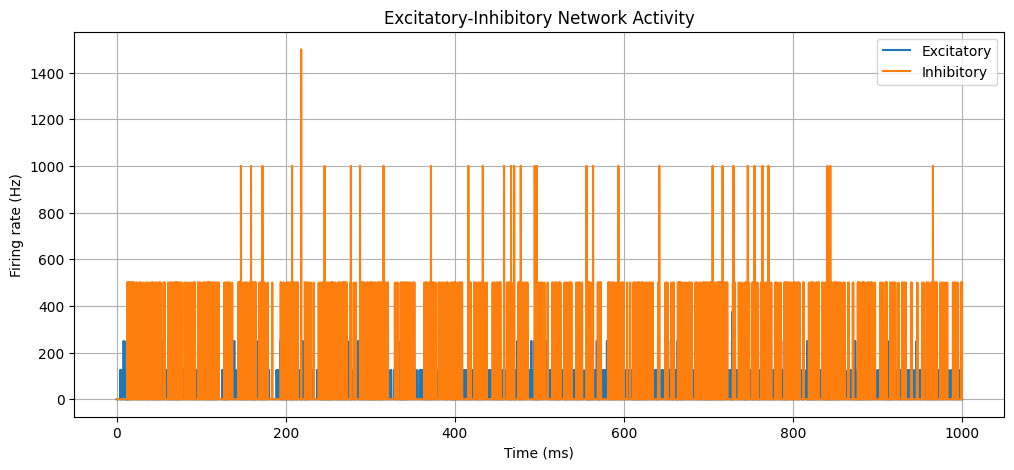

In [274]:
plt.figure(figsize=(12, 5))

plt.plot(
    rate_E.t/ms,
    rate_E.rate/Hz,
    label='Excitatory'
)

plt.plot(
    rate_I.t/ms,
    rate_I.rate/Hz,
    label='Inhibitory'
)

plt.xlabel('Time (ms)')
plt.ylabel('Firing rate (Hz)')
plt.title('Excitatory-Inhibitory Network Activity')

plt.legend()
plt.grid()

plt.show()

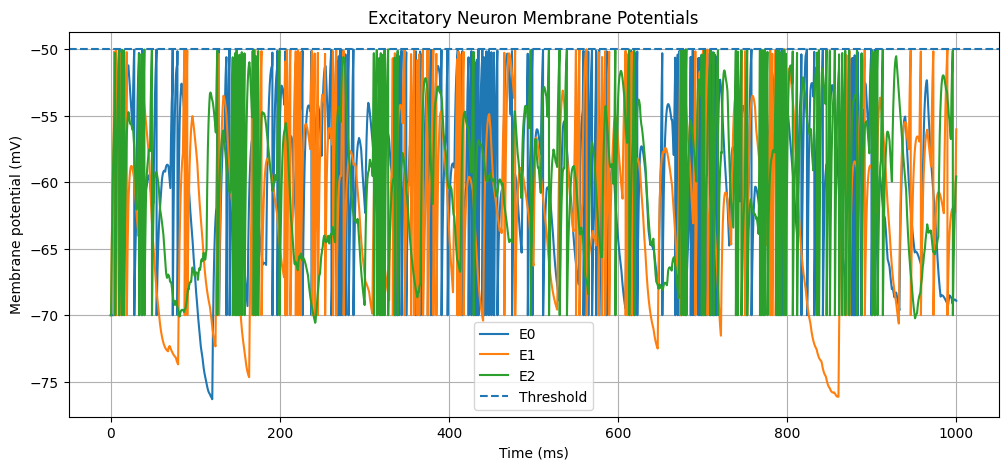

In [275]:
plt.figure(figsize=(12, 5))

for i in range(3):
    plt.plot(
        M_E.t/ms,
        M_E.v[i]/mV,
        label=f'E{i}'
    )

plt.axhline(
    Vth/mV,
    linestyle='--',
    label='Threshold'
)

plt.xlabel('Time (ms)')
plt.ylabel('Membrane potential (mV)')
plt.title('Excitatory Neuron Membrane Potentials')

plt.legend()
plt.grid()

plt.show()

In [276]:
print("======================================")
print("E/I NETWORK DIAGNOSTICS")
print("======================================")

print(f"Excitatory neurons : {N_E}")
print(f"Inhibitory neurons : {N_I}")

print(f"E -> E synapses   : {len(S_EE.i[:])}")
print(f"E -> I synapses   : {len(S_EI.i[:])}")
print(f"I -> E synapses   : {len(S_IE.i[:])}")
print(f"I -> I synapses   : {len(S_II.i[:])}")

print("--------------------------------------")

print(f"Excitatory spikes : {spikes_E.num_spikes}")
print(f"Inhibitory spikes : {spikes_I.num_spikes}")

print("--------------------------------------")

print(
    f"Mean E firing rate: "
    f"{np.mean(rate_E.rate/Hz):.2f} Hz"
)

print(
    f"Mean I firing rate: "
    f"{np.mean(rate_I.rate/Hz):.2f} Hz"
)

E/I NETWORK DIAGNOSTICS
Excitatory neurons : 80
Inhibitory neurons : 20
E -> E synapses   : 949
E -> I synapses   : 489
I -> E synapses   : 518
I -> I synapses   : 68
--------------------------------------
Excitatory spikes : 1382
Inhibitory spikes : 797
--------------------------------------
Mean E firing rate: 17.27 Hz
Mean I firing rate: 39.85 Hz


In [277]:
from brian2 import *
import matplotlib.pyplot as plt
import numpy as np

start_scope()

In [279]:
N_E = 80
N_I = 20

C = 200*pF
gL = 10*nS

EL = -70*mV
Vth = -50*mV
Vreset = -70*mV

E_exc = 0*mV
E_inh = -80*mV

tau_exc = 3*ms
tau_inh = 12*ms

In [280]:
eqs = '''
dv/dt = (
    gL*(EL-v)
    + g_exc*(E_exc-v)
    + g_inh*(E_inh-v)
) / C : volt

dg_exc/dt = -g_exc/tau_exc : siemens

dg_inh/dt = -g_inh/tau_inh : siemens
'''

In [281]:
E = NeuronGroup(
    N_E,
    eqs,
    threshold='v > Vth',
    reset='v = Vreset',
    refractory=2*ms,
    method='euler'
)

E.v = EL
E.g_exc = 0*nS
E.g_inh = 0*nS

In [282]:
I = NeuronGroup(
    N_I,
    eqs,
    threshold='v > Vth',
    reset='v = Vreset',
    refractory=2*ms,
    method='euler'
)

I.v = EL
I.g_exc = 0*nS
I.g_inh = 0*nS

In [283]:
S_EE = Synapses(
    E,
    E,
    on_pre='''
    g_exc_post += 1.2*nS
    '''
)

S_EE.connect(
    condition='i != j',
    p=0.12
)

WARNING    'j' is an internal variable of group 'synapses_11', but also exists in the run namespace with the value np.int32(0). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


In [284]:
S_EI = Synapses(
    E,
    I,
    on_pre='''
    g_exc_post += 3*nS
    '''
)

S_EI.connect(
    p=0.35
)

In [285]:
S_IE = Synapses(
    I,
    E,
    on_pre='''
    g_inh_post += 8*nS
    '''
)

S_IE.connect(
    p=0.45
)

In [286]:
S_II = Synapses(
    I,
    I,
    on_pre='''
    g_inh_post += 3*nS
    '''
)

S_II.connect(
    condition='i != j',
    p=0.20
)

WARNING    'i' is an internal variable of group 'synapses_8', but also exists in the run namespace with the value 2. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'j' is an internal variable of group 'synapses_8', but also exists in the run namespace with the value np.int32(0). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


In [287]:
stim = PoissonGroup(
    20,
    rates=80*Hz
)

In [288]:
S_input = Synapses(
    stim,
    E,
    on_pre='''
    g_exc_post += 12*nS
    '''
)

S_input.connect(
    j='i'
)

In [289]:
spikes_E = SpikeMonitor(E)
spikes_I = SpikeMonitor(I)

In [290]:
rate_E = PopulationRateMonitor(E)
rate_I = PopulationRateMonitor(I)

In [291]:
M_E = StateMonitor(
    E,
    'v',
    record=[0, 1, 2]
)

M_I = StateMonitor(
    I,
    'v',
    record=[0, 1, 2]
)

In [292]:
run(2*second)

In [293]:
print("Excitatory spikes:", spikes_E.num_spikes)
print("Inhibitory spikes:", spikes_I.num_spikes)

Excitatory spikes: 657
Inhibitory spikes: 1


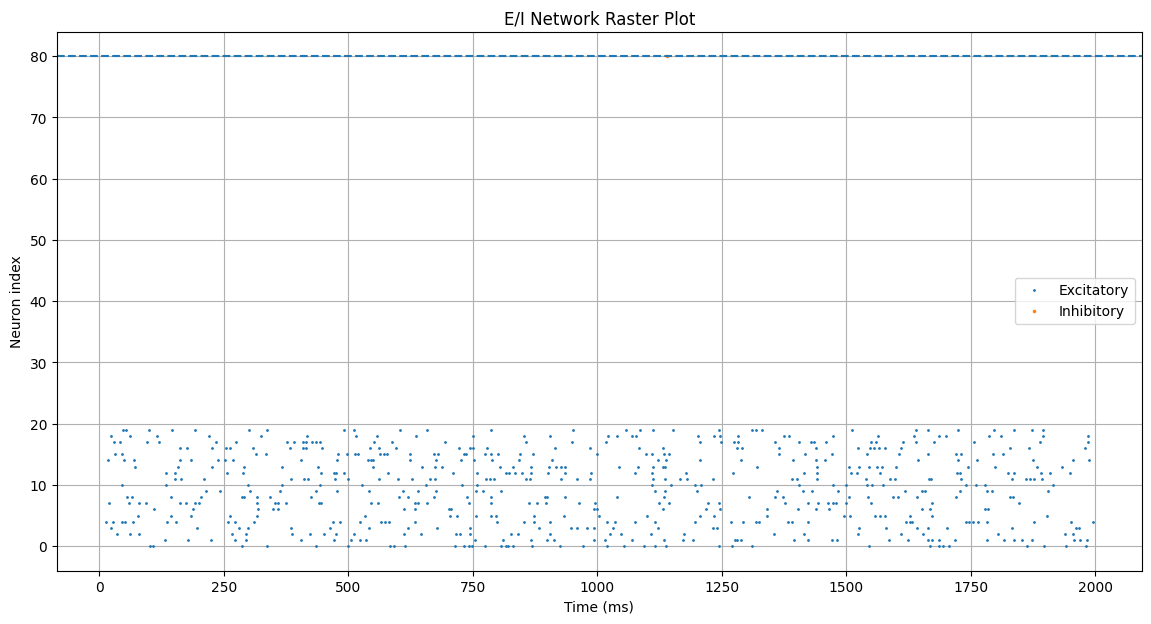

In [294]:
plt.figure(figsize=(14, 7))

plt.plot(
    spikes_E.t/ms,
    spikes_E.i,
    '.',
    markersize=2,
    label='Excitatory'
)

plt.plot(
    spikes_I.t/ms,
    spikes_I.i + N_E,
    '.',
    markersize=3,
    label='Inhibitory'
)

plt.axhline(
    N_E,
    linestyle='--'
)

plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('E/I Network Raster Plot')

plt.legend()
plt.grid()

plt.show()

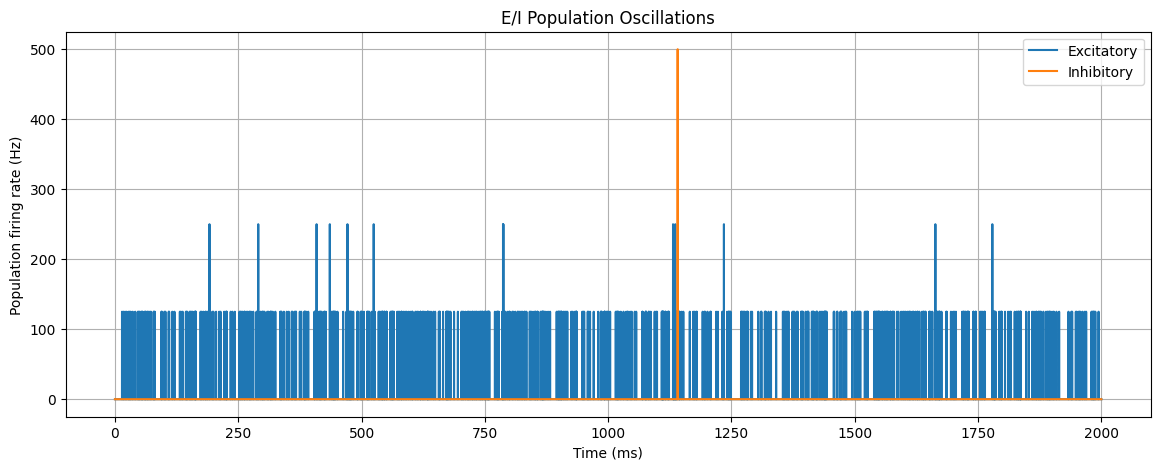

In [295]:
plt.figure(figsize=(14, 5))

plt.plot(
    rate_E.t/ms,
    rate_E.rate/Hz,
    label='Excitatory'
)

plt.plot(
    rate_I.t/ms,
    rate_I.rate/Hz,
    label='Inhibitory'
)

plt.xlabel('Time (ms)')
plt.ylabel('Population firing rate (Hz)')
plt.title('E/I Population Oscillations')

plt.legend()
plt.grid()

plt.show()

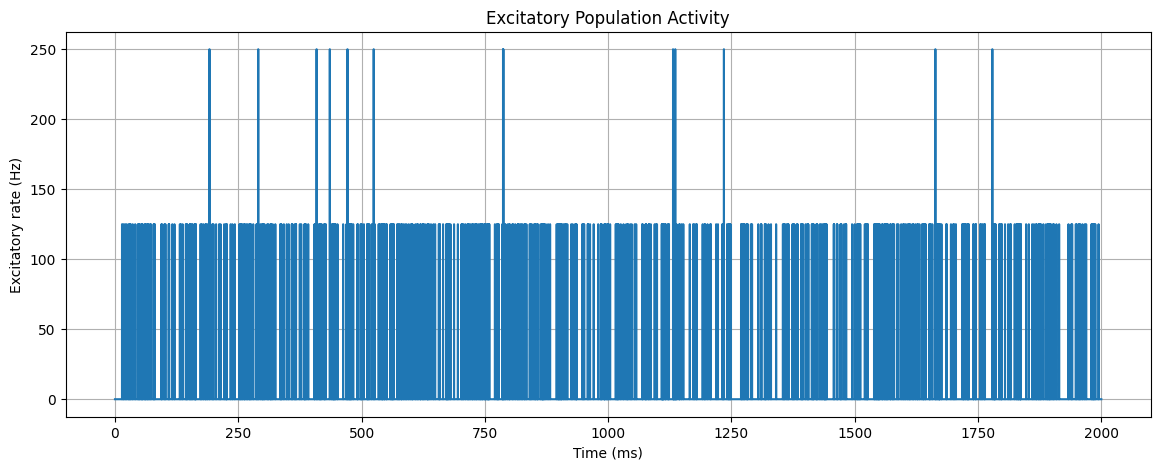

In [296]:
plt.figure(figsize=(14, 5))

plt.plot(
    rate_E.t/ms,
    rate_E.rate/Hz
)

plt.xlabel('Time (ms)')
plt.ylabel('Excitatory rate (Hz)')
plt.title('Excitatory Population Activity')

plt.grid()
plt.show()

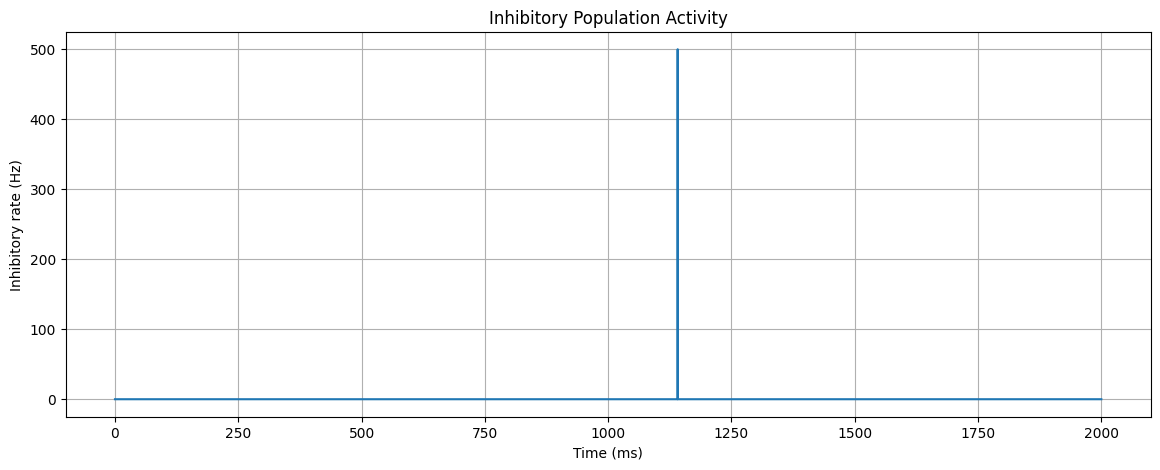

In [297]:
plt.figure(figsize=(14, 5))

plt.plot(
    rate_I.t/ms,
    rate_I.rate/Hz
)

plt.xlabel('Time (ms)')
plt.ylabel('Inhibitory rate (Hz)')
plt.title('Inhibitory Population Activity')

plt.grid()
plt.show()

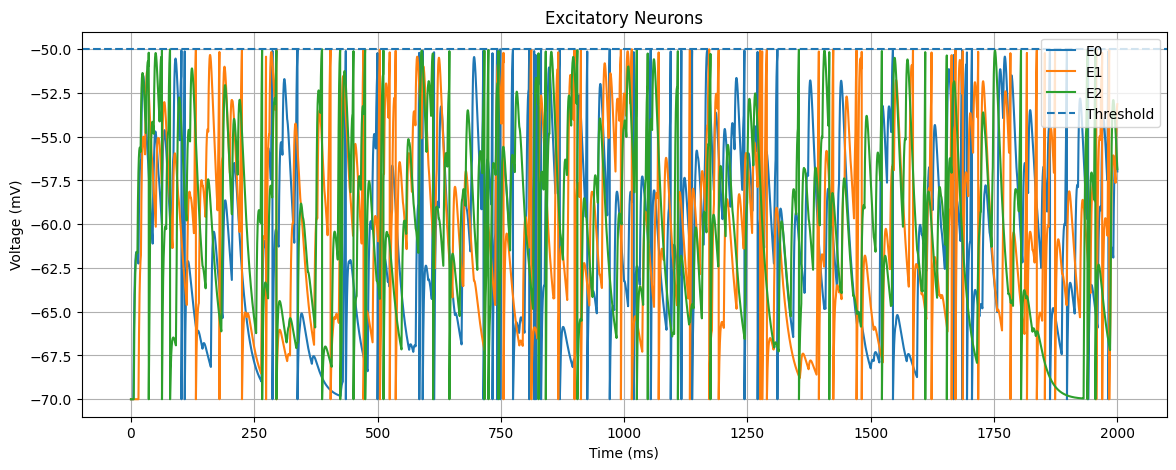

In [298]:
plt.figure(figsize=(14, 5))

for i in range(3):
    plt.plot(
        M_E.t/ms,
        M_E.v[i]/mV,
        label=f'E{i}'
    )

plt.axhline(
    Vth/mV,
    linestyle='--',
    label='Threshold'
)

plt.xlabel('Time (ms)')
plt.ylabel('Voltage (mV)')
plt.title('Excitatory Neurons')

plt.legend()
plt.grid()

plt.show()

In [299]:
population_rate = rate_E.rate / Hz

print(
    "Population-rate mean:",
    np.mean(population_rate),
    "Hz"
)

print(
    "Population-rate standard deviation:",
    np.std(population_rate),
    "Hz"
)

Population-rate mean: 4.10625 Hz
Population-rate standard deviation: 22.731750063237545 Hz


In [300]:
mean_rate = np.mean(population_rate)
std_rate = np.std(population_rate)

if mean_rate > 0:
    synchrony_index = std_rate / mean_rate
else:
    synchrony_index = 0

print(
    f"Population synchrony index: "
    f"{synchrony_index:.3f}"
)

Population synchrony index: 5.536


In [301]:
signal = population_rate - np.mean(population_rate)

dt_seconds = float(defaultclock.dt / second)

frequencies = np.fft.rfftfreq(
    len(signal),
    d=dt_seconds
)

power = np.abs(
    np.fft.rfft(signal)
)**2

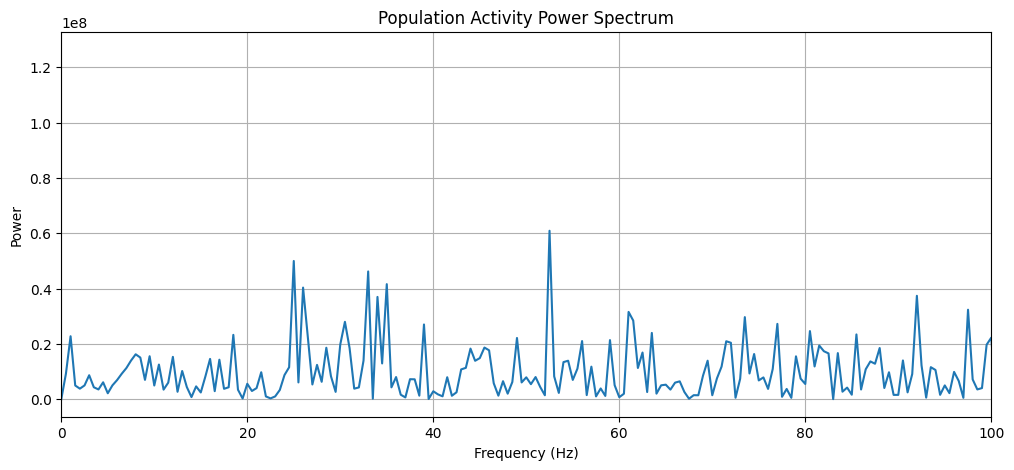

In [302]:
plt.figure(figsize=(12, 5))

plt.plot(
    frequencies,
    power
)

plt.xlim(0, 100)

plt.xlabel('Frequency (Hz)')
plt.ylabel('Power')
plt.title('Population Activity Power Spectrum')

plt.grid()

plt.show()

In [303]:
valid = frequencies > 1

dominant_frequency = frequencies[valid][
    np.argmax(power[valid])
]

print(
    f"Dominant frequency: "
    f"{dominant_frequency:.2f} Hz"
)

Dominant frequency: 3662.50 Hz
